# Cancer: AUTOENCODIX-Annealing mit den stärksten AUC-Korrelationen

Steuerungssignal: **MRRE false, Trustworthiness oder LCMC**, jeweils einzeln.
Die bisherige explorative Auswertung der 240 TCGA-Läufe motiviert diese Auswahl;
sie ist kein unabhängiger Wirksamkeitsnachweis für einen Annealer.

Wir verwenden den nativen AUTOENCODIX-Trainer und `VarixLoss`:
`Loss = Rekonstruktion + β_config × w × KL`. Unser Scheduler erhöht `w` stufenweise,
wenn die gewählte Metrik auf dem festen Validierungs-Subset über dem Zielband liegt,
und senkt ihn unterhalb des Zielbands. Im Band wird β gehalten und bei Abweichungen
wieder angepasst. Das ist eine beobachtete
Preservation-Grenze, keine harte mathematische Constraint der Modellgewichte.

**Rate ist nur Collapse-Diagnostik. AUC und Labels werden nie zur β-Steuerung verwendet.**
Standard: ein vorbereiteter TCGA-Lauf mit 1.000 Epochen; kein automatischer Start.
Ein Modell wird auf allen 33 Krebsarten trainiert und getrennt auf allen 33 sowie
den acht Präsentations-Krebsarten bewertet. Das sind keine zwei Trainingskohorten.
Die breite Large-Scale-Serie bleibt während dieses fokussierten Versuchs pausiert.

In [1]:
from pathlib import Path
from dataclasses import replace
import hashlib
import json
import os
import subprocess
import sys
import re
import time
from tqdm.auto import tqdm

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "beta_vae_experiments":
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "beta_vae_experiments" / "preservation_annealing.py").is_file():
    raise RuntimeError("Notebook aus dem Repo oder beta_vae_experiments öffnen.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from beta_vae_experiments.preservation_annealing import PreservationAnnealingConfig, measure_preservation
from beta_vae_experiments.metrics.information_theoretic import compute_conditional_kl_matrix
from beta_vae_experiments.metrics.latent_usage import PosteriorCollapseConfig

OUTPUT_ROOT = PROJECT_ROOT / "beta_vae_experiments" / "outputs" / "cancer_annealing_focus"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True})

## 1. Auswahl und Einstellungen

Die Tabelle unten zeigt die tatsächlich gespeicherten Pearson-/Spearman-Werte.
Wir wählen drei stark korrelierte lokale Preservation-Maße; sie sind untereinander
redundant und werden deshalb zunächst **einzeln** als Steuerungssignal getestet.

`METRICS = ("trustworthiness",)` bedeutet ein Modell. Für einen Vergleich alternativ
`("mrre_false", "trustworthiness", "lcmc")` wählen: dann entstehen drei Modelle.

`TARGET_MODE="absolute"`, `TARGET_VALUE=0.90`: Trustworthiness soll ungefähr
0,9 erreichen. Das ist ein absoluter Score, nicht 90 % des Warm-up-Werts.
Mit `ANNEALING_RULE="target"` wird β bei TW > 0,91 erhöht, bei TW < 0,89
gesenkt und im Zielband gehalten. Verlässt die Metrik das Band später wieder, wird
erneut angepasst. Bei Richtungswechseln werden die β-Schritte kleiner. Das Modell
trainiert bis Epoche 1.000; Rate und AUC steuern weiterhin nichts.

Messung alle 5 Epochen und Wachstumsfaktor 1,25 ergeben gröbere, schnellere Stufen. Snapshots
bleiben aus Speichergründen alle 20 Epochen. Modelllernen und Messintervalle können
Überschwingen verursachen; eine exakt eingehaltene harte 0,9-Grenze wird nicht zugesichert.
Wird zuerst der β-Deckel erreicht, zeigt das Notebook dies als eigenen Stoppgrund.

Für spätere relative Versuche: `TARGET_MODE="relative_warmup"` setzen; dann ist der
Wert ein Anteil des Warm-up-Scores. MRRE false und LCMC sind ebenfalls höher-besser;
LCMC kann negativ werden und benötigt für relative Ziele eine positive Referenz.

`PRESET="tcga_pilot"`: 1.000 Epochen, d=8, Seed 17, GPU.
`PRESET="cpu_demo"`: 30 Epochen mit Circle in 8 Latentdimensionen, nur Anbindungstest.
Mit `RUN_TRAINING=False` werden nur vorhandene Resultate geladen.

In [2]:
CANDIDATES = {"mrre_false": "geometry_mu_mrre_false_zadu_k20",
              "trustworthiness": "geometry_mu_trustworthiness_zadu_k20",
              "lcmc": "geometry_mu_lcmc_zadu_k20"}
summary_path = PROJECT_ROOT / "beta_vae_experiments/analysis_results/metric_selection/auc_correlations_summary.csv"
summary = pd.read_csv(summary_path)
selection = summary[summary.task.eq("cancer") & summary["mode"].eq("values")
                    & summary.metric.isin(CANDIDATES.values())]
display(selection[["metric", "pearson", "spearman", "gain_spearman", "n_trajectories"]]
        .sort_values("pearson", ascending=False))

PRESET = "tcga_pilot"
METRICS = ("trustworthiness",)
TARGET_MODE = "absolute"
ANNEALING_RULE = "target"
TARGET_TOLERANCE = 0.01
TARGET_VALUE = 0.90
TARGET_SCORES = {metric: TARGET_VALUE for metric in CANDIDATES}
RUN_TRAINING = True
RERUN_COMPLETED = False
SEED, SPLIT_SEED = 17, 2
PRESETS = {
    "tcga_pilot": dict(epochs=1000, latent_dim=8, device="cuda", beta_over_d=0.015,
                       warmup_epochs=100, step_epochs=5, n_subsample=800, k=20,
                       every=20, w_min=0.0001, growth=1.25),
    "cpu_demo": dict(epochs=30, latent_dim=8, device="cpu", beta_over_d=1.0,
                     warmup_epochs=10, step_epochs=5, n_subsample=120, k=10,
                     every=5, w_min=0.001, growth=2.0),
}
parameters = PRESETS[PRESET].copy()
assert METRICS and set(METRICS) <= CANDIDATES.keys()
display(pd.Series(parameters, name=PRESET).to_frame())

,metric,pearson,spearman,gain_spearman,n_trajectories
23,geometry_mu_mrre_false_zadu_k20,0.990318,0.97619,0.0,24
39,geometry_mu_trustworthiness_zadu_k20,0.988134,0.97619,0.0,24
21,geometry_mu_lcmc_zadu_k20,0.984278,0.97619,0.0,24


,tcga_pilot
epochs,1000
latent_dim,8
device,cuda
beta_over_d,0.015
warmup_epochs,100
step_epochs,5
n_subsample,800
k,20
every,20
w_min,0.0001


## 2. Eine native Trainingskonfiguration je gewählter Metrik

Gleiche Daten, gleicher Split, gleicher Seed. Der Quellstand des Annealers und die
Konfiguration gehen in den Ergebnisordner-Namen ein, damit alte Ergebnisse nicht
versehentlich als neue Experimente geladen werden.
Nur Posteriors, native Loss-Logs und Snapshots werden beim Pilot erzeugt.
Die gezielte Auswertung unten berechnet ausschließlich die drei gewählten
Preservation-Maße, Rate/ε-δ und Cancer-AUC. Die breite Metrik-Pipeline läuft hier nicht.

In [3]:
def make_notebook_config(metric):
    settings = json.loads((PROJECT_ROOT / "beta_vae_experiments/user_interface/quickstart.json").read_text())
    if PRESET == "cpu_demo":
        settings["dataset"] = dict(id="circle", split_seed=SPLIT_SEED,
                                   options=dict(n_samples=600, dataset_seed=42, radius=1.0))
    else:
        from beta_vae_experiments.user_interface.config import load_config
        source = load_config(str(PROJECT_ROOT / "beta_vae_experiments/user_interface/experiments.json") + "#training.tcga")
        settings["dataset"] = source["dataset"]
        settings["dataset"]["split_seed"] = SPLIT_SEED
        options = settings["dataset"]["options"]
        options["data_root"] = str((PROJECT_ROOT / options["data_root"]).resolve())
        settings["training"]["downstream_targets"] = ["CANCER_TYPE_ACRONYM"]
    controller = dict(mode="preservation", metric=metric, target=TARGET_SCORES[metric],
                      target_mode=TARGET_MODE, rule=ANNEALING_RULE, tolerance=TARGET_TOLERANCE,
                      max_invalid_measurements=3,
                      warmup_epochs=parameters["warmup_epochs"], step_epochs=parameters["step_epochs"],
                      n_subsample=parameters["n_subsample"], k=parameters["k"], seed=31,
                      w_min=parameters["w_min"], growth=parameters["growth"])
    PreservationAnnealingConfig(**controller)
    training = settings["training"]
    training.pop("betas", None)
    training.update(beta_over_d=[parameters["beta_over_d"]], latent_dims=[parameters["latent_dim"]],
                    epochs=parameters["epochs"], device=parameters["device"], seeds=[SEED],
                    anneal_function="3phase-linear", beta_controller=controller,
                    snapshots=dict(enabled=True, every=parameters["every"], downstream=False))
    settings["metrics"]["absolute_core"]["enabled"] = False
    settings["plots"] = dict(enabled=False, per_run=False)
    settings["execution"] = dict(resume_existing=True, rerun_passed=RERUN_COMPLETED)
    settings.pop("output_dir", None)
    settings.pop("experiment_name", None)
    settings["controller_source_sha256"] = hashlib.sha256((PROJECT_ROOT / "beta_vae_experiments/preservation_annealing.py").read_bytes()).hexdigest()
    fingerprint = hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()[:10]
    name = f"{PRESET}_{metric}_{fingerprint}"
    settings.update(experiment_name=name, output_dir=str(OUTPUT_ROOT / name))
    return settings

configs = {metric: make_notebook_config(metric) for metric in METRICS}
config_paths = {}
config_folder = OUTPUT_ROOT / "configs"
config_folder.mkdir(exist_ok=True)
for metric, settings in configs.items():
    path = config_folder / f"{settings['experiment_name']}.json"
    path.write_text(json.dumps(settings, indent=2) + "\n")
    config_paths[metric] = path

environment = {**os.environ, "PYTHONHASHSEED": "2", "MPLCONFIGDIR": "/tmp/mpl-preservation-notebook",
               "OMP_NUM_THREADS": "1", "OPENBLAS_NUM_THREADS": "1", "CUBLAS_WORKSPACE_CONFIG": ":4096:8"}
for path in config_paths.values():
    subprocess.run([sys.executable, "-m", "beta_vae_experiments.new_beta_varix_experiments",
                    str(path), "--preflight"], cwd=PROJECT_ROOT, env=environment, check=True)
display(pd.DataFrame([dict(variant=m, output=s["output_dir"], epochs=parameters["epochs"])
                      for m, s in configs.items()]))

Preflight passed: tcga_pilot_trustworthiness_a6c397d237 (tcga, 1 runs)


,variant,output,epochs
0,trustworthiness,/home/nickok/Projects/MasterThesis/vae-beta-co...,1000


### Training mit Live-Fortschritt
**Run All** startet den konfigurierten Lauf oder beobachtet den bereits laufenden Prozess. Der Balken zeigt abgeschlossene Epochen, effektives β und die letzte gemessene Trustworthiness (Ziel: 0,90). Während der Warm-up-Phase ist noch kein Messwert verfügbar. Das vollständige Trainingslog bleibt gespeichert.


Mit `LIVE_DASHBOARD = True` erscheint darunter das Live-Dashboard (siehe unten): Es liest nur die Dateien im Run-Ordner und rechnet bei jedem neuen Snapshot (alle 20 Epochen) Rate, ε-δ-Collapse, Patienten-Collapse, labelfreien Cluster-Overlap und die AUTOENCODIX-UMAP von z. Der Overlap steht zusätzlich als Text darunter und in `live_summary.md` im Run-Ordner.

In [4]:
LIVE_DASHBOARD = True  # Live-Dashboard während des Trainings anzeigen

from beta_vae_experiments.live_dashboard import LiveDashboard


def show_progress(bar, run_folder, log_path, dashboard=None):
    """Show completed validation epochs, the latest controller signal and, if given, the live dashboard."""
    if dashboard is not None:
        dashboard.refresh()
    if log_path.exists():
        epochs = re.findall(r"Epoch (\d+) - Valid Loss:", log_path.read_text(errors="replace"))
        if epochs:
            bar.update(max(0, min(int(epochs[-1]), bar.total) - bar.n))
    logs = sorted((run_folder / "run_analysis").glob("*/controller_log.csv"))
    if logs:
        try:
            history = pd.read_csv(logs[-1])
            if not history.empty:
                latest = history.iloc[-1]
                measured = history.dropna(subset=["metric_value"])
                signal = f"{measured.iloc[-1].metric_value:.3f}" if len(measured) else "warmup"
                bar.set_postfix(beta=f"{latest.effective_beta:.3g}", TW=signal,
                                target=TARGET_VALUE, state=latest.state)
        except (pd.errors.EmptyDataError, pd.errors.ParserError):
            pass  # The training process may currently be writing the CSV.


for metric, path in config_paths.items():
    run_folder = Path(configs[metric]["output_dir"])
    manifest = run_folder / "launcher.json"
    launcher = json.loads(manifest.read_text()) if manifest.exists() else {}
    active = launcher.get("status") in {"running", "analysing"}
    if active:
        try:
            os.kill(int(launcher["pid"]), 0)  # Check liveness without sending a signal.
        except ProcessLookupError:
            raise RuntimeError(f"Veralteter Laufstatus: {manifest}; bitte vor Neustart prüfen.")
        log_path = Path(launcher["log"])
        print("Bestehenden Lauf beobachten; kein zweites Training. Interrupt beendet nur die Anzeige.")
        dashboard = LiveDashboard(run_folder).show() if LIVE_DASHBOARD else None
        with tqdm(total=parameters["epochs"], desc=f"TCGA · {metric}", unit="epoch") as bar:
            while True:
                show_progress(bar, run_folder, log_path, dashboard)
                launcher = json.loads(manifest.read_text())
                if launcher["status"] not in {"running", "analysing"}:
                    if launcher["status"] != "complete":
                        raise RuntimeError(f"Laufstatus: {launcher['status']}; siehe {log_path}")
                    break
                bar.set_description(f"TCGA · {metric}" if launcher["status"] == "running"
                                    else "Training fertig · Auswertung läuft")
                time.sleep(2)
    elif RUN_TRAINING:
        log_path = OUTPUT_ROOT / f"{configs[metric]['experiment_name']}.log"
        dashboard = LiveDashboard(run_folder).show() if LIVE_DASHBOARD else None
        with log_path.open("w") as log, tqdm(
            total=parameters["epochs"], desc=f"TCGA · {metric}", unit="epoch"
        ) as bar:
            process = subprocess.Popen(
                [sys.executable, "-u", "-m", "beta_vae_experiments.new_beta_varix_experiments", str(path)],
                cwd=PROJECT_ROOT, env=environment, stdout=subprocess.PIPE,
                stderr=subprocess.STDOUT, text=True,
            )
            try:
                for line in process.stdout:
                    log.write(line)
                    log.flush()
                    if " - Valid Loss:" in line:
                        show_progress(bar, run_folder, log_path, dashboard)
                if process.wait():
                    raise RuntimeError(f"Training fehlgeschlagen; siehe {log_path}")
                show_progress(bar, run_folder, log_path, dashboard)
                if dashboard is not None:
                    dashboard.refresh(force=True)
            except BaseException:
                if process.poll() is None:
                    process.terminate()
                process.wait()
                raise
    else:
        print("Kein Training gestartet; vorhandene Ergebnisse werden geladen.")


TCGA · trustworthiness:   0%|          | 0/1000 [00:00<?, ?epoch/s]

### Live-Dashboard und Rückblick auf fertige Läufe

Dasselbe Dashboard für einen fertigen Lauf: Der Schieberegler wählt den Snapshot, die UMAP und der Overlap-Text gelten für
diese Epoche (violette Linie). Werte werden einmal pro Snapshot gerechnet und in `live_metrics.csv`,
`live_descriptions.json` und `live_summary.md` im Run-Ordner gespeichert; danach lädt der Rückblick nur noch.

**Labelfreier Cluster-Overlap** (`cluster_overlap.py`): k-means auf X (800 Validierungspatienten des Controllers), Clusterzahl
nach bester Silhouette (ZADU). Für jeden Snapshot: Anteil der 20 nächsten Nachbarn im eigenen X-Cluster (ZADU
`neighborhood_hit`, in X, μ und z), Wiederfinden der X-Cluster (k-means im Latentraum, ARI über ZADU), eigene Clusterzahl
des Latentraums und die Cluster-Paare, die am stärksten zusammenwachsen. Die Krebsarten in Klammern benennen die Cluster
nur; gerechnet wird ohne Labels.

In [ ]:
BROWSE_RUN = OUTPUT_ROOT / "tcga_pilot_trustworthiness_a6c397d237"  # oder bab147caaa (Ziel 0,7), a7bee9448a (Ziel 0,9, 500 Ep.)
LiveDashboard(BROWSE_RUN).browse()

## 4. β und Steuerungssignal auf Validation

β steigt nur über die gewählte Preservation-Metrik. Rate oder AUC werden hier nicht
verwendet. Ein ungültiger Wert ist kein Nullwert: β wird zurückgenommen; nach drei
aufeinanderfolgenden ungültigen Messungen schlägt der Lauf explizit fehl.
Wir prüfen die Übereinstimmung mit den tatsächlich verwendeten nativen Loss-Faktoren.

trustworthiness {'not_measured': 819, 'ok': 181}
Zielkorridor mindestens einmal erreicht: True
Letzter Zustand/Grund: {'state': 'hold', 'reason': 'target_band'}


,epoch,w,effective_beta,metric_value,target,state,status,warning
99,100,0.000000,0.000000,0.959779,0.9,warmup,ok,NaN
104,105,0.000100,0.000012,0.966905,0.9,seeking,ok,NaN
109,110,0.000125,0.000015,0.966815,0.9,seeking,ok,NaN
114,115,0.000156,0.000019,0.966935,0.9,seeking,ok,NaN
119,120,0.000195,0.000023,0.968165,0.9,seeking,ok,NaN
...,...,...,...,...,...,...,...,...
979,980,0.080779,0.009694,0.895609,0.9,hold,ok,NaN
984,985,0.080779,0.009694,0.895951,0.9,hold,ok,NaN
989,990,0.080779,0.009694,0.896529,0.9,hold,ok,NaN
994,995,0.080779,0.009694,0.898134,0.9,hold,ok,NaN


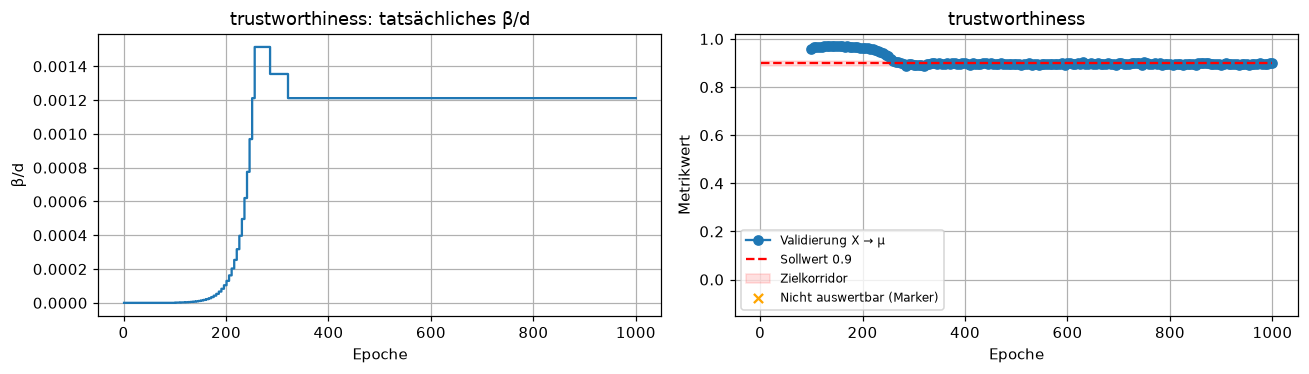

In [5]:
runs, controller_tables, loss_tables = {}, {}, {}
for metric, settings in configs.items():
    output = Path(settings["output_dir"])
    overview_path = output / "experiment_metrics.csv"
    if not overview_path.exists():
        print(f"{metric}: noch kein Lauf; RUN_TRAINING aktivieren, wenn die Einstellungen passen.")
        continue
    overview = pd.read_csv(overview_path)
    if len(overview) != 1 or not overview.status.eq("ok").all():
        raise RuntimeError(overview.to_string())
    folder = output / "run_analysis" / overview.iloc[0].run_name
    runs[metric] = folder
    controller = pd.read_csv(folder / "controller_log.csv")
    losses = pd.read_csv(folder / "epoch_losses.csv")
    if len(controller) != parameters["epochs"]:
        raise ValueError("Controller-Log enthält nicht alle Epochen.")
    for split in ("train", "valid"):
        compared = controller.merge(losses[losses.split.eq(split)], on="epoch")
        if len(compared) != len(controller):
            raise ValueError("Loss- und Controller-Epochen stimmen nicht überein.")
        np.testing.assert_allclose(compared.effective_beta, compared.effective_beta_factor, rtol=1e-7, atol=1e-12)
    controller_tables[metric] = controller
    loss_tables[metric] = losses
    print(metric, controller.status.value_counts().to_dict())
    reached = (controller.metric_value.notna() & ((controller.metric_value-controller.target).abs() <= controller.tolerance + 1e-12)).any()
    print("Zielkorridor mindestens einmal erreicht:", bool(reached))
    if "reason" in controller:
        print("Letzter Zustand/Grund:", controller.iloc[-1][["state", "reason"]].to_dict())
    if not controller.status.eq("ok").any():
        print("ACHTUNG: Kein gültiges Steuerungssignal; dies ist kein erfolgreicher Annealing-Nachweis.")
    display(controller.loc[~controller.status.eq("not_measured"),
        ["epoch", "w", "effective_beta", "metric_value", "target", "state", "status", "warning"]])

if runs:
    fig, axes = plt.subplots(len(METRICS), 2, figsize=(12, 3.5 * len(METRICS)), squeeze=False)
    for row, metric in enumerate(METRICS):
        table = controller_tables[metric]
        axes[row, 0].step(table.epoch, table.beta_over_d, where="post")
        axes[row, 0].set(title=f"{metric}: tatsächliches β/d", xlabel="Epoche", ylabel="β/d")
        measured = table[table.status.eq("ok")]
        axes[row, 1].plot(measured.epoch, measured.metric_value, "o-", label="Validierung X → μ")
        axes[row, 1].plot(table.epoch, table.target, color="red", linestyle="--", label=f"Sollwert {TARGET_VALUE:g}")
        axes[row, 1].fill_between(table.epoch, table.target-table.tolerance, table.target+table.tolerance, color="red", alpha=.12, label="Zielkorridor")
        missing = table[table.status.eq("unavailable")]
        axes[row, 1].scatter(missing.epoch, np.full(len(missing), 0.03), marker="x", color="orange", label="Nicht auswertbar (Marker)")
        axes[row, 1].set(title=metric, xlabel="Epoche", ylabel="Metrikwert", ylim=(-0.15, 1.02))
        axes[row, 1].legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(OUTPUT_ROOT / f"{PRESET}_beta_and_preservation.png", dpi=160)
    plt.show()

## 5. Drei Preservation-Signale und Collapse-Diagnostik

Die gespeicherte Controller-Referenz enthält nur das feste Validierungs-Subset,
keine Labels. Für jedes Snapshot werden dieselben IDs und dieselben X-Werte benutzt.
Die beiden zusätzlichen Metriken werden nachträglich mit den Bibliotheken berechnet.
Fehlende oder nicht auswertbare Werte bleiben gekennzeichnet.

Rate = mittlere Gesamt-KL in Nats pro Patient. ε-δ-Collapse: mindestens 99 % der
Patienten einer Dimension haben KL < 0,01. Beides sind hier Diagnosen, keine β-Eingaben.

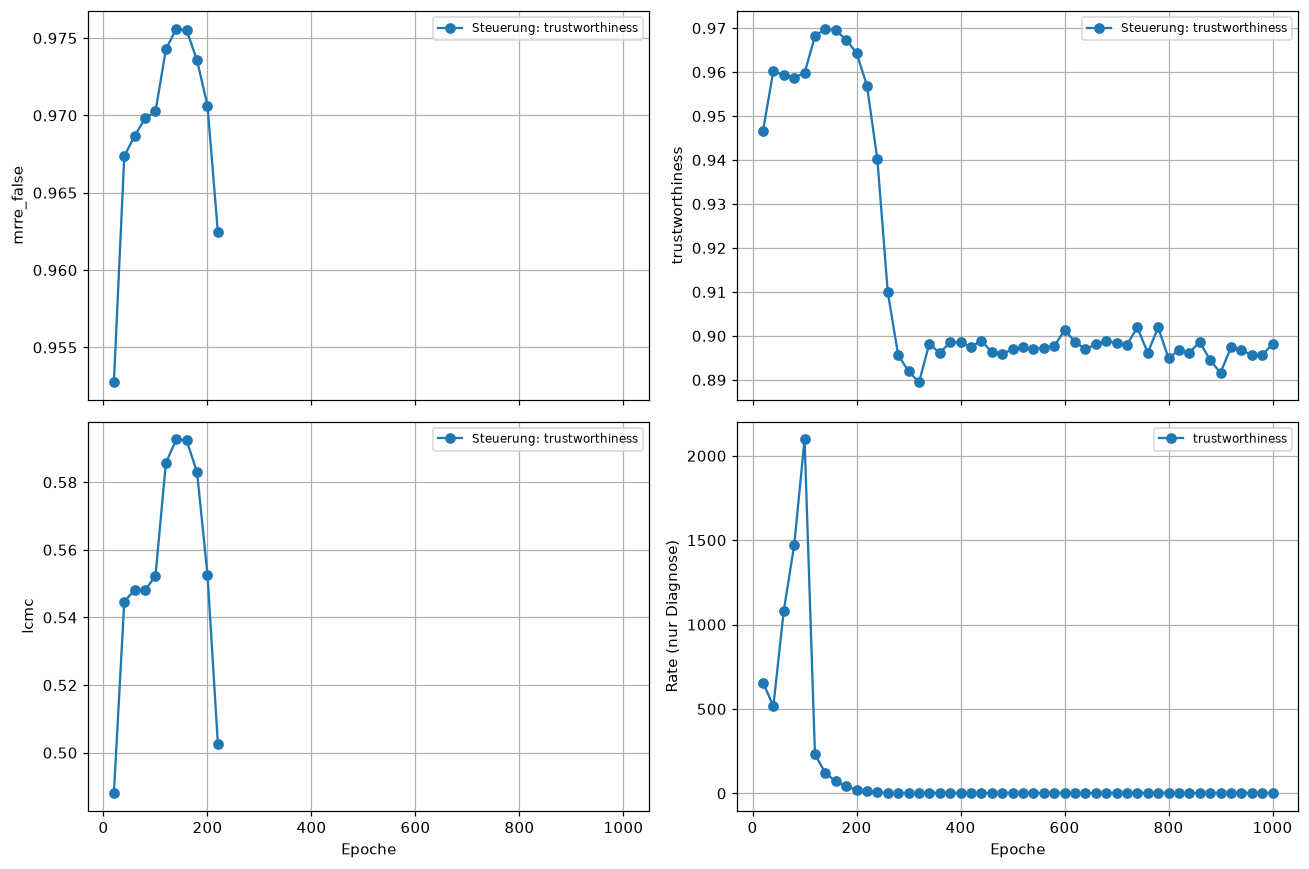

,variant,epoch,rate,collapsed_dimensions,status
0,trustworthiness,20,656.699988,0,ok
1,trustworthiness,40,516.985608,0,ok
2,trustworthiness,60,1082.330722,0,ok
3,trustworthiness,80,1469.638675,0,ok
4,trustworthiness,100,2096.886719,0,ok
5,trustworthiness,120,230.718567,0,ok
6,trustworthiness,140,120.029845,0,ok
7,trustworthiness,160,70.396507,0,ok
8,trustworthiness,180,40.764958,0,ok
9,trustworthiness,200,22.720143,0,ok


In [6]:
posterior_rows, comparison_rows = [], []
collapse = PosteriorCollapseConfig()
for variant, folder in runs.items():
    policy = PreservationAnnealingConfig(**json.loads((folder / "controller_config.json").read_text())["settings"])
    with np.load(folder / "controller_validation_reference.npz") as reference:
        x_reference = reference["x"]
        reference_ids = reference["sample_ids"].astype(str)
    for path in sorted((folder / "epoch_snapshots").glob("epoch_*_valid.npz")):
        epoch = int(path.stem.split("_")[1])
        with np.load(path) as saved:
            if not {"mu", "logvar", "sample_ids"} <= set(saved.files):
                posterior_rows.append(dict(variant=variant, epoch=epoch, status="missing_posterior"))
                continue
            positions = pd.Index(saved["sample_ids"].astype(str)).get_indexer(reference_ids)
            if (positions < 0).any():
                raise ValueError("Validation-Kohorte hat sich geändert")
            mu, logvar = saved["mu"][positions], saved["logvar"][positions]
        kl = compute_conditional_kl_matrix(mu, logvar)
        posterior_rows.append(dict(variant=variant, epoch=epoch, rate=kl.sum(1).mean(),
            collapsed_dimensions=int(np.sum(np.mean(kl < collapse.primary_epsilon, axis=0) >= 1-collapse.delta)), status="ok"))
        for metric in CANDIDATES:
            value, status, warning = np.nan, "ok", None
            try:
                value = measure_preservation(x_reference, mu, replace(policy, metric=metric))
            except (ValueError, RuntimeError, KeyError, ZeroDivisionError) as error:
                status, warning = "unavailable", str(error)
            comparison_rows.append(dict(variant=variant, epoch=epoch, metric=metric, value=value, status=status, warning=warning))
posterior = pd.DataFrame(posterior_rows, columns=["variant", "epoch", "rate", "collapsed_dimensions", "status"])
comparisons = pd.DataFrame(comparison_rows, columns=["variant", "epoch", "metric", "value", "status", "warning"])
posterior.to_csv(OUTPUT_ROOT / f"{PRESET}_rate_collapse.csv", index=False)
comparisons.to_csv(OUTPUT_ROOT / f"{PRESET}_selected_metrics.csv", index=False)
if runs:
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
    for ax, metric in zip(axes.flat, CANDIDATES):
        for variant, group in comparisons[comparisons.metric.eq(metric)].groupby("variant"):
            ax.plot(group.epoch, group.value, "o-", label=f"Steuerung: {variant}")
        ax.set_ylabel(metric); ax.legend(fontsize=8)
    for variant, group in posterior.groupby("variant"):
        axes[1, 1].plot(group.epoch, group.rate, "o-", label=variant)
    axes[1, 1].set_ylabel("Rate (nur Diagnose)")
    for ax in axes[-1]: ax.set_xlabel("Epoche")
    axes[1, 1].legend(fontsize=8)
    fig.tight_layout(); fig.savefig(OUTPUT_ROOT / f"{PRESET}_metrics_and_rate.png", dpi=160)
    plt.show()
    display(posterior)
else:
    print("Noch keine trainierten Modelle für die Snapshot-Auswertung.")

## 6. Cancer-AUC: acht und alle 33 Krebsarten

Die Auswertung nutzt gespeichertes z und den nativen AUTOENCODIX-Presplit-Evaluator:
Logistische Regression auf Train, AUC auf Validation, alle Klassen ohne Top-20-Limit.
Acht Präsentationsklassen: BRCA, COAD, LUAD, LUSC, OV, READ, UCEC, UCS.
Das Training nutzt weiterhin die vollständige Kohorte; die Acht-Klassen-Auswertung
ist ein zweiter nachträglicher Probe auf denselben Modell-Snapshots.

Die Prozenttabelle zeigt für den ersten beobachteten relativen AUC-Abfall von 5 %,
wie viel des jeweiligen Metrik-Ausgangswerts im letzten Snapshot davor vorhanden war.
Referenz ist der erste gespeicherte Snapshot nach dem Warm-up. Ohne beobachteten
Abfall wird kein Kipppunkt erfunden. Das ist eine nachträgliche Analyse, keine
Schwellenoptimierung und kein Beweis zeitlicher Frühwarnung.

/home/nickok/Projects/MasterThesis/vae-beta-control/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/nickok/Projects/MasterThesis/vae-beta-control/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
   

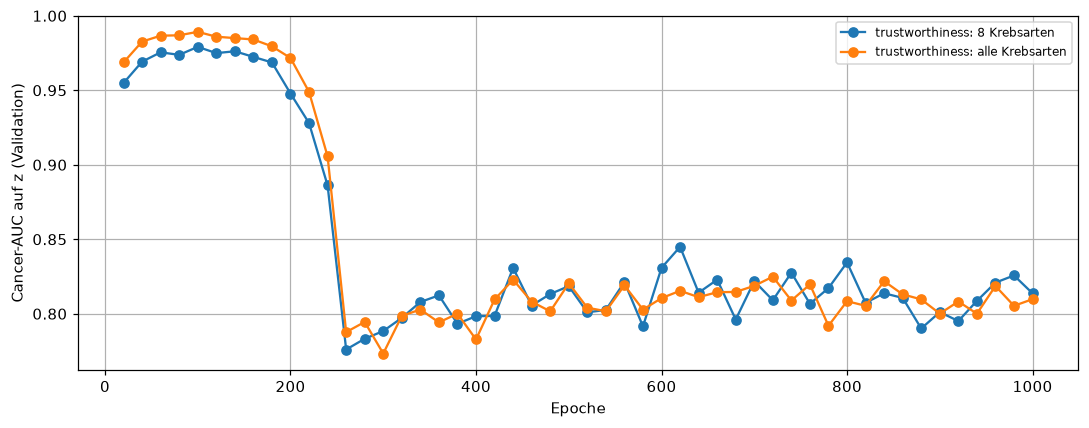

,variant,cohort,metric,baseline_epoch,last_before_drop,first_drop,metric_retained_percent,status
0,trustworthiness,8 Krebsarten,mrre_false,100,200,220,100.038521,Beobachteter Abfall
1,trustworthiness,8 Krebsarten,trustworthiness,100,200,220,100.473758,Beobachteter Abfall
2,trustworthiness,8 Krebsarten,lcmc,100,200,220,100.056577,Beobachteter Abfall
3,trustworthiness,alle Krebsarten,mrre_false,100,220,240,99.193725,Beobachteter Abfall
4,trustworthiness,alle Krebsarten,trustworthiness,100,220,240,99.702178,Beobachteter Abfall
5,trustworthiness,alle Krebsarten,lcmc,100,220,240,90.992927,Beobachteter Abfall


Ergebnisse: /home/nickok/Projects/MasterThesis/vae-beta-control/beta_vae_experiments/outputs/cancer_annealing_focus


In [7]:
from sklearn.linear_model import LogisticRegression
from beta_vae_experiments.metrics.evaluation.downstream import ClassAUCEvaluator

CANCERS_8 = ("BRCA", "COAD", "LUAD", "LUSC", "OV", "READ", "UCEC", "UCS")
auc_rows = []
for variant, folder in runs.items():
    label_path = folder / "epoch_snapshots" / "labels_train.parquet"
    if not label_path.exists() or "CANCER_TYPE_ACRONYM" not in pd.read_parquet(label_path):
        print(variant, ": CPU-Demo hat keine Krebslabels; keine Cancer-AUC erfunden.")
        continue
    for path in sorted((folder / "epoch_snapshots").glob("epoch_*_valid.npz")):
        epoch = int(path.stem.split("_")[1])
        for cohort in ("8 Krebsarten", "alle Krebsarten"):
            features, annotations, partitions = [], [], []
            for split in ("train", "valid"):
                with np.load(folder / "epoch_snapshots" / f"epoch_{epoch:05d}_{split}.npz") as saved:
                    ids, z = saved["sample_ids"].astype(str), saved["z"]
                labels = pd.read_parquet(folder / "epoch_snapshots" / f"labels_{split}.parquet")
                labels.index = labels.index.astype(str); labels = labels.loc[ids]
                keep = labels.CANCER_TYPE_ACRONYM.isin(CANCERS_8) if cohort == "8 Krebsarten" else np.ones(len(labels), dtype=bool)
                selected_ids = ids[np.asarray(keep)]
                features.append(pd.DataFrame(z[np.asarray(keep)], index=selected_ids))
                annotations.append(labels.loc[selected_ids, ["CANCER_TYPE_ACRONYM"]])
                partitions.append(pd.DataFrame(dict(SAMPLE_ID=selected_ids, SPLIT=split)))
            value, status, warning = np.nan, "ok", None
            try:
                scores = ClassAUCEvaluator()._single_ml_presplit(
                    pd.concat(partitions, ignore_index=True), pd.concat(features), pd.concat(annotations),
                    "CANCER_TYPE_ACRONYM", LogisticRegression(max_iter=1000), "roc_auc_ovo", "classification", top_k_classes=None)
                value = float(scores.loc[scores.score_split.eq("valid"), "value"].iloc[0])
                if not np.isfinite(value): status = "unavailable"
            except (ValueError, IndexError) as error:
                status, warning = "unavailable", str(error)
            auc_rows.append(dict(variant=variant, epoch=epoch, cohort=cohort, auc=value, status=status, warning=warning))
auc = pd.DataFrame(auc_rows, columns=["variant", "epoch", "cohort", "auc", "status", "warning"])
auc.to_csv(OUTPUT_ROOT / f"{PRESET}_cancer_auc.csv", index=False)
if not auc.empty:
    fig, ax = plt.subplots(figsize=(10, 4))
    for (variant, cohort), group in auc.groupby(["variant", "cohort"]):
        ax.plot(group.epoch, group.auc, "o-", label=f"{variant}: {cohort}")
    ax.set(xlabel="Epoche", ylabel="Cancer-AUC auf z (Validation)"); ax.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(OUTPUT_ROOT / f"{PRESET}_cancer_auc.png", dpi=160); plt.show()
    retained = []
    for (variant, cohort), group in auc[auc.status.eq("ok")].groupby(["variant", "cohort"]):
        group = group[group.epoch >= parameters["warmup_epochs"]].sort_values("epoch")
        if group.empty: continue
        first = group.iloc[0]
        drops = group[group.auc < 0.95 * first.auc]
        if drops.empty:
            retained.append(dict(variant=variant, cohort=cohort, status="Kein 5%-Abfall beobachtet")); continue
        crossing = drops.iloc[0]
        before = group[group.epoch < crossing.epoch].iloc[-1]
        for metric in CANDIDATES:
            trajectory = comparisons[(comparisons.variant == variant) & comparisons.metric.eq(metric)].set_index("epoch")
            baseline = trajectory.loc[first.epoch, "value"]
            value = trajectory.loc[before.epoch, "value"]
            retained.append(dict(variant=variant, cohort=cohort, metric=metric, baseline_epoch=first.epoch,
                last_before_drop=before.epoch, first_drop=crossing.epoch,
                metric_retained_percent=100*value/baseline if baseline > 0 else np.nan, status="Beobachteter Abfall"))
    retention = pd.DataFrame(retained)
    retention.to_csv(OUTPUT_ROOT / f"{PRESET}_preservation_before_auc_drop.csv", index=False)
    display(retention)
else:
    print("Cancer-AUC wird erst nach einem TCGA-Lauf ausgewertet.")
print("Ergebnisse:", OUTPUT_ROOT)

## Was dieser Versuch beantwortet

- Kann die gewählte hoch korrelierte Preservation-Metrik das native β-Annealing steuern?
- Wie verhalten sich Rate und ε-δ-Collapse dabei, ohne als Regelsignal zu dienen?
- Bleibt Cancer-AUC auf z erhalten, für acht und alle Krebsarten?
- Wie viel Preservation war unmittelbar vor einem beobachteten AUC-Abfall noch vorhanden?

Hohe Korrelation allein garantiert weder Downstream-Erhalt noch Collapse-Vermeidung.
Erst diesen fokussierten Versuch prüfen, danach Large Scale mit dem geprüften Stand
fortsetzen. Der Quellstand hat sich geändert; die frühere Serienfreigabe wird nicht
ungeprüft wiederverwendet. Es wird keine Metrikformel im Notebook nachgebaut.

## 7. Überblick: Ziel 0,7 gegen Ziel 0,9 (500 und 1.000 Epochen)

Alle Läufe: TCGA, d = 8, Seed 17, 100 Epochen Warm-up, Messung alle 5 Epochen.
Ziel 0,7: 1.000 Epochen, Wachstumsfaktor 1,10. Ziel 0,9: 500 bzw. 1.000 Epochen, Wachstumsfaktor 1,25 (bis Epoche 500 identisch).
β/d und Trustworthiness stammen aus dem Controller-Log (Validierungs-Subset, alle 5 Epochen),
Rate und Cancer-AUC aus den Snapshots (alle 20 Epochen, AUC auf z, Validation).
Die Sammeldateien des 0,7-Laufs liegen in `summary_target_0.70/`, weil `tcga_pilot_*` vom
jeweils letzten Lauf überschrieben wird; die des 0,9-Laufs mit 500 Epochen in `summary_target_0.90_500ep/`.
Der 1.000-Epochen-Lauf ist ausführlich in `trustworthiness_09.ipynb` ausgewertet.

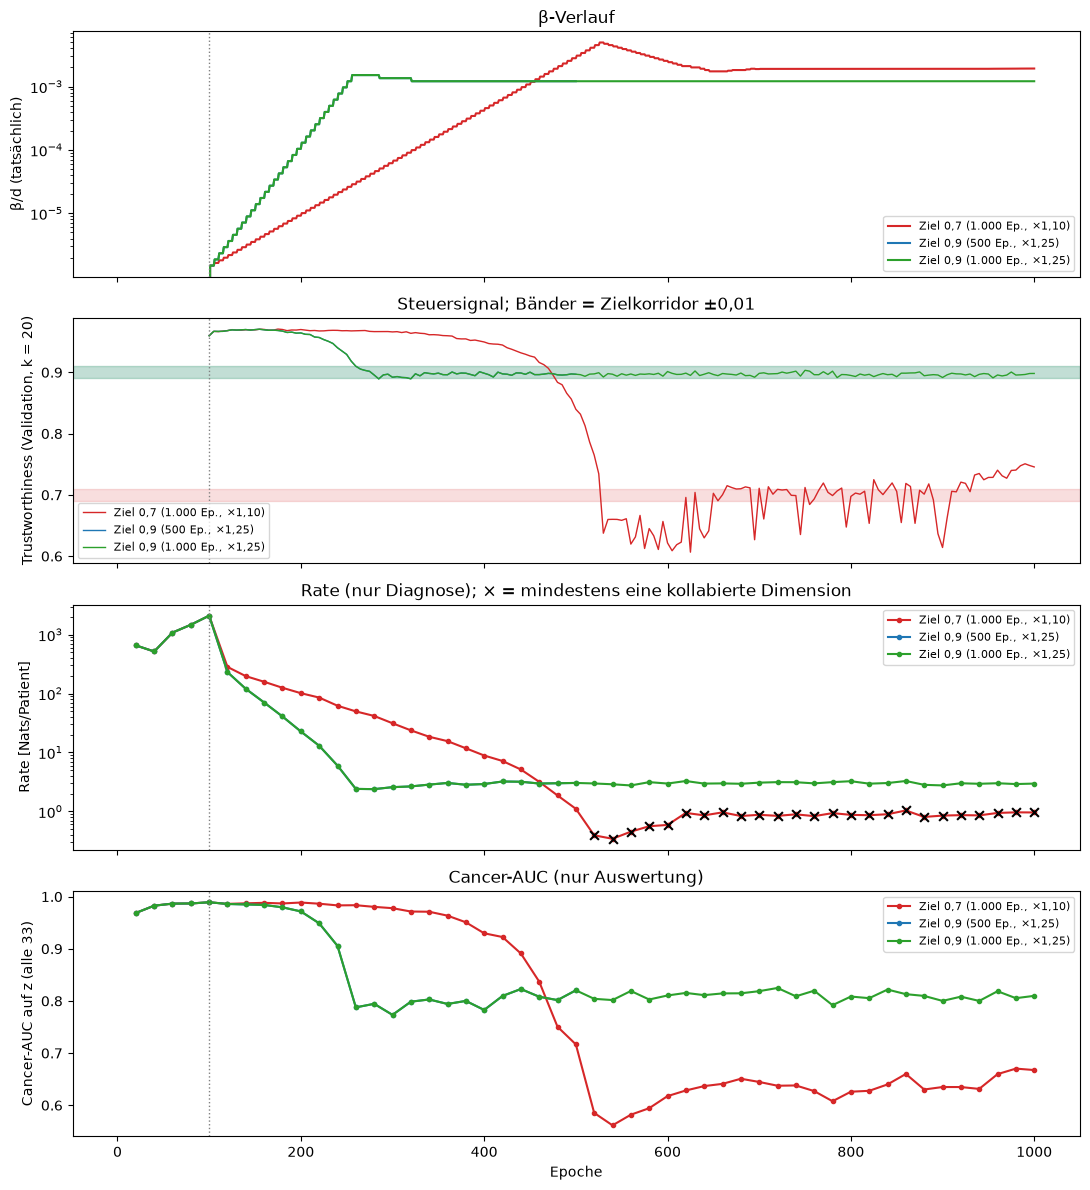

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

FOCUS = Path.cwd() / "outputs" / "cancer_annealing_focus" if Path.cwd().name == "beta_vae_experiments" \
    else Path.cwd() / "beta_vae_experiments" / "outputs" / "cancer_annealing_focus"
COMPARED = {
    "Ziel 0,7 (1.000 Ep., ×1,10)": ("tcga_pilot_trustworthiness_bab147caaa", FOCUS / "summary_target_0.70"),
    "Ziel 0,9 (500 Ep., ×1,25)": ("tcga_pilot_trustworthiness_a7bee9448a", FOCUS / "summary_target_0.90_500ep"),
    "Ziel 0,9 (1.000 Ep., ×1,25)": ("tcga_pilot_trustworthiness_a6c397d237", FOCUS),
}
fig, axes = plt.subplots(4, 1, figsize=(11, 12), sharex=True)
for (label, (run, summary)), color in zip(COMPARED.items(), ("tab:red", "tab:blue", "tab:green")):
    controller = pd.read_csv(next((FOCUS / run / "run_analysis").glob("*/controller_log.csv")))
    measured = controller.dropna(subset=["metric_value"])
    rate = pd.read_csv(summary / "tcga_pilot_rate_collapse.csv")
    auc = pd.read_csv(summary / "tcga_pilot_cancer_auc.csv")
    auc = auc[auc.cohort.eq("alle Krebsarten")]
    target = controller.target.iloc[-1]
    axes[0].plot(controller.epoch, controller.beta_over_d, color=color, label=label)
    axes[1].plot(measured.epoch, measured.metric_value, color=color, lw=1, label=label)
    axes[1].axhspan(target - controller.tolerance.iloc[-1], target + controller.tolerance.iloc[-1], color=color, alpha=.15)
    axes[2].plot(rate.epoch, rate.rate, "o-", ms=3, color=color, label=label)
    collapsed = rate[rate.collapsed_dimensions > 0]
    axes[2].scatter(collapsed.epoch, collapsed.rate, marker="x", s=40, color="black", zorder=3)
    axes[3].plot(auc.epoch, auc.auc, "o-", ms=3, color=color, label=label)
axes[0].set(yscale="log", ylabel="β/d (tatsächlich)", title="β-Verlauf")
axes[1].set(ylabel="Trustworthiness (Validation, k = 20)", title="Steuersignal; Bänder = Zielkorridor ±0,01")
axes[2].set(yscale="log", ylabel="Rate [Nats/Patient]", title="Rate (nur Diagnose); × = mindestens eine kollabierte Dimension")
axes[3].set(ylabel="Cancer-AUC auf z (alle 33)", xlabel="Epoche", title="Cancer-AUC (nur Auswertung)")
for ax in axes:
    ax.axvline(100, color="gray", ls=":", lw=1)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FOCUS / "tcga_pilot_target_0.7_vs_0.9.png", dpi=160)
plt.show()

## 8. Collapse-Analyse: was zuerst, was zuletzt, was danach, und bei welchem Wert

Vier Fragen an die beiden Annealing-Läufe (d = 8, Seed 17):

1. **Was wird zuerst zerstört, was zuletzt?** Pro Signal die Epoche (und das β/d), ab der es 2 %, 5 % bzw. 20 % schlechter ist als am Ende des Warm-ups.
2. **Welche Dimensionen kollabieren, und was trugen sie?** KL je Dimension über die Epochen und der Anteil der μ-Varianz je Dimension, den Krebsart bzw. Geschlecht erklären (η²).
3. **Was passiert nach dem Collapse?** Erholen sich Rate, Dimensionen, Preservation und AUC, wenn der Controller β danach wieder senkt?
4. **Bei welchem Trustworthiness- bzw. MRRE-false-Wert liegt der Collapse?** Im Annealing-Lauf und, mit 24 Trajektorien, im β-Sweep.

Der Lauf mit Ziel 0,7 kollabiert, der Lauf mit Ziel 0,9 nicht; er dient als Vergleich.
Grundlage sind die Snapshots alle 20 Epochen (μ, logvar, z für Train und Validation).
Collapse wie oben: ε-δ, mindestens 99 % der Patienten einer Dimension mit KL < 0,01.
Preservation auf dem festen Controller-Subset (800 Validierungspatienten, k = 20),
AUC auf z (Logistische Regression auf Train, AUC auf Validation). Labels werden nur ausgewertet.

**Wichtig für die Interpretation: μ ist in Varix nach unten abgeschnitten.**
AUTOENCODIX setzt im Encoder `mu = torch.where(mu < 1e-7, 0, mu)` (`autoencodix/modeling/_varix_architecture.py`, Zeile 129),
zusätzlich zur bekannten Klemme `logvar ∈ [0,01; 20]`. Jede μ-Koordinate ist also ≥ 0 und wirkt wie hinter einer ReLU:
unterhalb der Schwelle ist sie exakt 0 und bekommt **keinen Gradienten** mehr. Der KL-Term zieht μ Richtung 0, also genau an
diese Kante. Deshalb werden unten zwei zusätzliche Collapse-Signale mitgeführt: der Anteil der μ-Einträge, die exakt 0 sind,
und der Anteil der Patienten, deren μ in **allen** Dimensionen 0 ist (Patienten-Collapse: diese Patienten sind in μ nicht mehr
unterscheidbar). Solche Duplikate machen die ZADU-Maße (MRRE false, LCMC, Cohesiveness) ab einem Zeitpunkt nicht mehr
berechenbar; ZADU verweigert doppelte Punkte. Trustworthiness (sklearn) bleibt messbar.

In [2]:
from pathlib import Path
from dataclasses import replace
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display
from sklearn.linear_model import LogisticRegression
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "beta_vae_experiments" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from beta_vae_experiments.preservation_annealing import PreservationAnnealingConfig, measure_preservation
from beta_vae_experiments.metrics.information_theoretic import compute_conditional_kl_matrix
from beta_vae_experiments.metrics.evaluation.downstream import ClassAUCEvaluator

FOCUS = PROJECT_ROOT / "beta_vae_experiments" / "outputs" / "cancer_annealing_focus"
COLLAPSE_ROOT = FOCUS / "collapse_analysis"
COLLAPSE_ROOT.mkdir(exist_ok=True)
COLLAPSE_RUNS = {"Ziel 0,7": "tcga_pilot_trustworthiness_bab147caaa",
                 "Ziel 0,9": "tcga_pilot_trustworthiness_a7bee9448a"}
RUN_COLORS = {"Ziel 0,7": "#c0392b", "Ziel 0,9": "#2471a3", "Ziel 0,9 (1.000 Ep.)": "#16a085"}
EPS, DELTA = 0.01, 0.01
PRESERVATION = ("trustworthiness", "mrre_false", "lcmc", "cohesiveness")
REFERENCE_EPOCH = 100  # Ende des Warm-ups (β = 0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "legend.frameon": False})


def run_folder(run):
    return next((FOCUS / COLLAPSE_RUNS[run] / "run_analysis").glob("*/controller_config.json")).parent


def auc_on_z(folder, epoch, target):
    """AUC of a logistic regression on z: fit on train, score on validation."""
    features, annotations, partitions = [], [], []
    for split in ("train", "valid"):
        with np.load(folder / "epoch_snapshots" / f"epoch_{epoch:05d}_{split}.npz") as saved:
            ids, z = saved["sample_ids"].astype(str), saved["z"]
        labels = pd.read_parquet(folder / "epoch_snapshots" / f"labels_{split}.parquet")
        labels.index = labels.index.astype(str)
        labels = labels.loc[ids, [target]]
        keep = labels[target].notna().to_numpy()
        features.append(pd.DataFrame(z[keep], index=ids[keep]))
        annotations.append(labels[keep])
        partitions.append(pd.DataFrame(dict(SAMPLE_ID=ids[keep], SPLIT=split)))
    scores = ClassAUCEvaluator()._single_ml_presplit(
        pd.concat(partitions, ignore_index=True), pd.concat(features), pd.concat(annotations),
        target, LogisticRegression(max_iter=1000), "roc_auc_ovo", "classification", top_k_classes=None)
    return float(scores.loc[scores.score_split.eq("valid"), "value"].iloc[0])


def eta_squared(values, groups):
    """Share of the variance of one latent coordinate explained by a categorical label."""
    frame = pd.DataFrame(dict(v=values, g=groups)).dropna()
    total = ((frame.v - frame.v.mean()) ** 2).sum()
    between = frame.groupby("g").v.agg(lambda s: len(s) * (s.mean() - frame.v.mean()) ** 2).sum()
    return between / total if total > 0 else np.nan


snapshot_cache, dimension_cache = COLLAPSE_ROOT / "snapshots.csv", COLLAPSE_ROOT / "dimensions.csv"
snapshots = pd.read_csv(snapshot_cache) if snapshot_cache.exists() else pd.DataFrame(columns=["run"])
dimensions = pd.read_csv(dimension_cache) if dimension_cache.exists() else pd.DataFrame(columns=["run"])
missing_runs = [run for run in COLLAPSE_RUNS if run not in set(snapshots.run) or run not in set(dimensions.run)]
if missing_runs:  # nur neue Läufe berechnen, vorhandene aus dem Zwischenspeicher übernehmen
    snapshots, dimensions = snapshots[~snapshots.run.isin(missing_runs)], dimensions[~dimensions.run.isin(missing_runs)]
    snapshot_rows, dimension_rows = [], []
    for run in missing_runs:
        folder = run_folder(run)
        policy = PreservationAnnealingConfig(**json.loads((folder / "controller_config.json").read_text())["settings"])
        controller = pd.read_csv(folder / "controller_log.csv").set_index("epoch")
        losses = pd.read_csv(folder / "epoch_losses.csv")
        recon = losses[losses.split.eq("valid")].set_index("epoch").recon_loss
        with np.load(folder / "controller_validation_reference.npz") as reference:
            x_reference, reference_ids = reference["x"], reference["sample_ids"].astype(str)
        valid_labels = pd.read_parquet(folder / "epoch_snapshots" / "labels_valid.parquet")
        valid_labels.index = valid_labels.index.astype(str)
        for path in sorted((folder / "epoch_snapshots").glob("epoch_*_valid.npz")):
            epoch = int(path.stem.split("_")[1])
            with np.load(path) as saved:
                ids, mu, logvar = saved["sample_ids"].astype(str), saved["mu"], saved["logvar"]
            kl = compute_conditional_kl_matrix(mu, logvar)
            collapsed = np.mean(kl < EPS, axis=0) >= 1 - DELTA
            positions = pd.Index(ids).get_indexer(reference_ids)
            row = dict(run=run, epoch=epoch, beta_over_d=controller.loc[epoch, "beta_over_d"],
                       rate=kl.sum(1).mean(), collapsed_dimensions=int(collapsed.sum()),
                       zero_entries=float((mu == 0).mean()), zero_patients=float((mu == 0).all(1).mean()),
                       recon_valid=recon.loc[epoch],
                       auc_cancer=auc_on_z(folder, epoch, "CANCER_TYPE_ACRONYM"),
                       auc_sex=auc_on_z(folder, epoch, "SEX"))
            for metric in PRESERVATION:
                try:
                    row[metric] = measure_preservation(x_reference, mu[positions], replace(policy, metric=metric))
                except (ValueError, RuntimeError, KeyError, ZeroDivisionError):
                    row[metric] = np.nan
            snapshot_rows.append(row)
            labels = valid_labels.loc[ids]
            for dim in range(mu.shape[1]):
                dimension_rows.append(dict(
                    run=run, epoch=epoch, dim=dim, kl_mean=kl[:, dim].mean(), collapsed=bool(collapsed[dim]),
                    zero_fraction=float((mu[:, dim] == 0).mean()), mu_std=mu[:, dim].std(),
                    eta2_cancer=eta_squared(mu[:, dim], labels.CANCER_TYPE_ACRONYM.to_numpy()),
                    eta2_sex=eta_squared(mu[:, dim], labels.SEX.to_numpy())))
    snapshots = pd.concat([snapshots, pd.DataFrame(snapshot_rows)], ignore_index=True)
    dimensions = pd.concat([dimensions, pd.DataFrame(dimension_rows)], ignore_index=True)
    snapshots.to_csv(snapshot_cache, index=False)
    dimensions.to_csv(dimension_cache, index=False)
snapshots = snapshots[snapshots.run.isin(COLLAPSE_RUNS)].astype({"epoch": int}).reset_index(drop=True)
dimensions = dimensions[dimensions.run.isin(COLLAPSE_RUNS)].astype({"epoch": int, "dim": int}).reset_index(drop=True)
dimensions["collapsed"] = dimensions.collapsed.astype(bool)
snapshots["active_dimensions"] = 8 - snapshots.collapsed_dimensions
NCOLS = len(COLLAPSE_RUNS)
WIDTHS = [snapshots[snapshots.run.eq(run)].epoch.max() for run in COLLAPSE_RUNS]
first_collapse = snapshots[snapshots.collapsed_dimensions > 0].groupby("run").epoch.min()
zadu_gone = snapshots[snapshots.mrre_false.isna()].groupby("run").epoch.min()
display(pd.DataFrame(dict(
    snapshots=snapshots.groupby("run").size(), erste_kollabierte_dimension=first_collapse,
    erster_patient_bei_mu_0=snapshots[snapshots.zero_patients > 0].groupby("run").epoch.min(),
    zadu_nicht_messbar_ab=zadu_gone, max_kollabierte_dimensionen=snapshots.groupby("run").collapsed_dimensions.max())))

,snapshots,erste_kollabierte_dimension,erster_patient_bei_mu_0,zadu_nicht_messbar_ab,max_kollabierte_dimensionen
run,,,,,
"Ziel 0,7",50,520.0,340,380,5
"Ziel 0,9",25,NaN,240,240,0


### 8.1 Was wird zuerst zerstört, was zuletzt?

Referenz ist der Snapshot am Ende des Warm-ups (Epoche 100, β = 0). Für jedes Signal wird der relative Verlust
gegenüber dieser Referenz in der jeweils schlechten Richtung berechnet: Preservation und AUC fallen,
Rekonstruktionsfehler steigt, aktive Dimensionen = 8 − kollabierte. Die Zeitleiste zeigt die erste Snapshot-Epoche,
ab der 2 % (kleiner Kreis), 5 % (mittel) bzw. 20 % (groß) Verlust erreicht sind; die Signale sind nach dem 5 %-Zeitpunkt
sortiert. Schraffiert: ab hier nicht messbar (Patienten bei μ = 0). Die Rate ist die Ursache und steht deshalb nicht
in der Rangliste, sondern oben im Verlaufsplot. Snapshots liegen 20 Epochen auseinander.

run,signal,epoch_2%,beta_over_d_2%,epoch_5%,beta_over_d_5%,epoch_20%,beta_over_d_20%,nicht_messbar_ab,max_verlust_%
"Ziel 0,7",Rekonstruktionsfehler,120,0.000002,200,0.000009,320,0.000090,–,142.628684
"Ziel 0,7",AUC Geschlecht,320,0.000090,320,0.000090,460,0.001303,–,42.623961
"Ziel 0,7",Cohesiveness,300,0.000062,340,0.000132,–,–,380,11.435072
"Ziel 0,7",AUC Krebsart,360,0.000194,400,0.000415,480,0.001908,–,43.243454
"Ziel 0,7",Trustworthiness,440,0.000890,480,0.001908,520,0.004090,–,36.015737
"Ziel 0,7",aktive Dimensionen,520,0.004090,520,0.004090,520,0.004090,–,62.500000
"Ziel 0,7",LCMC,340,0.000132,–,–,–,–,380,4.910891
"Ziel 0,7",MRRE false,–,–,–,–,–,–,380,0.432539
"Ziel 0,9",Rekonstruktionsfehler,120,0.000003,140,0.000007,200,0.000104,–,98.124191
"Ziel 0,9",AUC Geschlecht,200,0.000104,200,0.000104,260,0.001515,–,25.600685


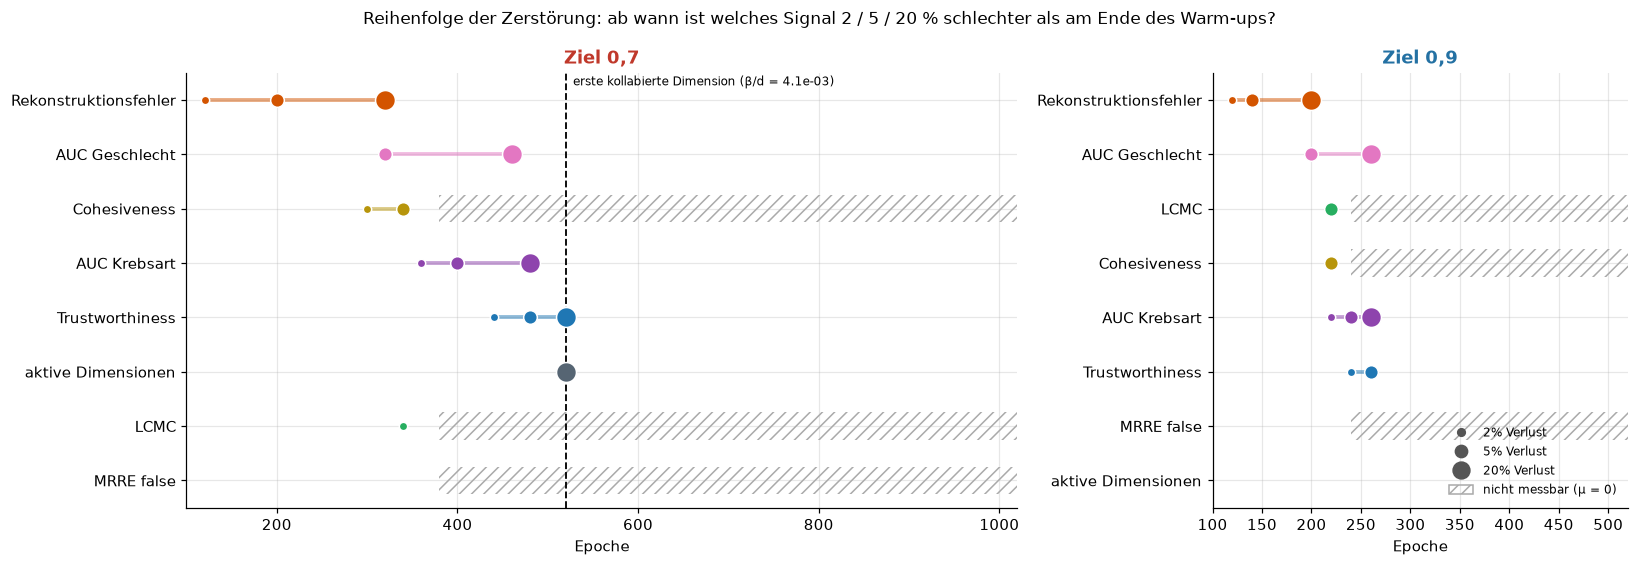

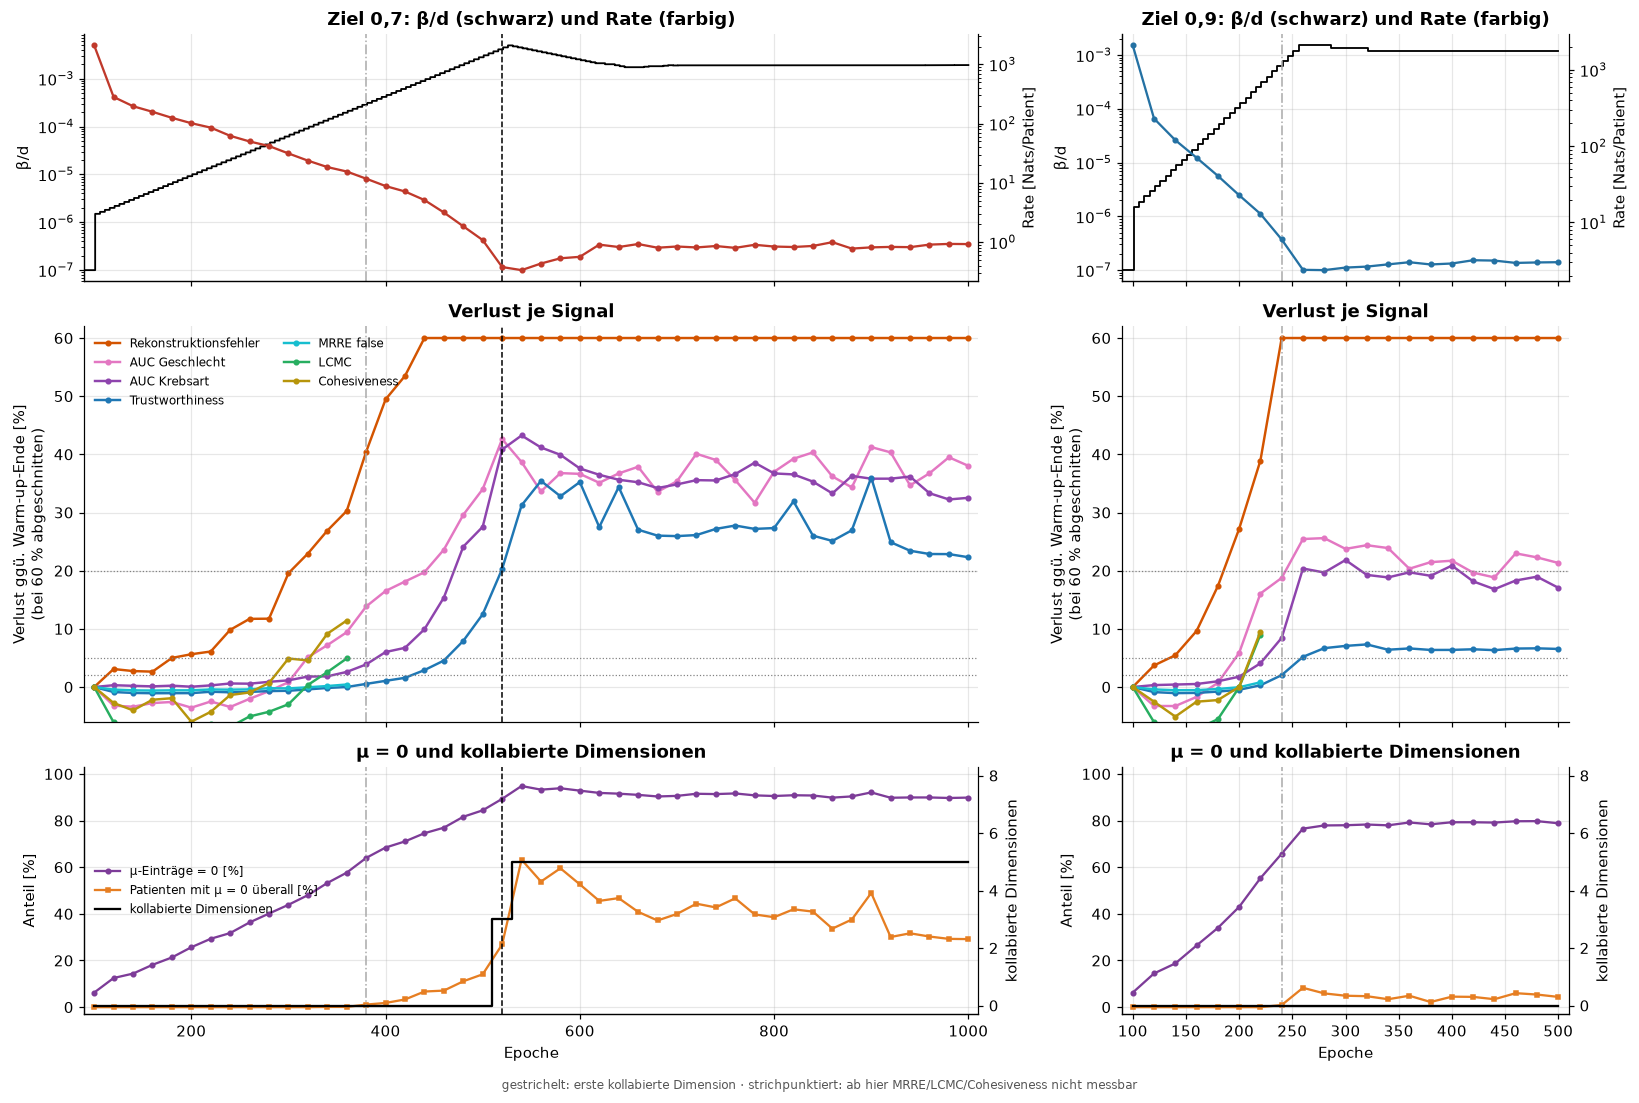

In [3]:
SIGNALS = {"recon_valid": ("Rekonstruktionsfehler", -1, "#d35400"),
           "auc_sex": ("AUC Geschlecht", +1, "#e377c2"),
           "auc_cancer": ("AUC Krebsart", +1, "#8e44ad"),
           "trustworthiness": ("Trustworthiness", +1, "#1f77b4"),
           "mrre_false": ("MRRE false", +1, "#17becf"),
           "lcmc": ("LCMC", +1, "#27ae60"),
           "cohesiveness": ("Cohesiveness", +1, "#b7950b"),
           "active_dimensions": ("aktive Dimensionen", +1, "#566573")}
THRESHOLDS = (0.02, 0.05, 0.20)


def relative_loss(group, column, direction):
    reference = group.loc[group.epoch.eq(REFERENCE_EPOCH), column].iloc[0]
    change = (group[column] - reference) / abs(reference)
    return -change if direction > 0 else change


order_rows = []
for run, group in snapshots.groupby("run"):
    group = group[group.epoch >= REFERENCE_EPOCH].sort_values("epoch").reset_index(drop=True)
    for column, (label, direction, _) in SIGNALS.items():
        loss = relative_loss(group, column, direction)
        row = dict(run=run, signal=label)
        for threshold in THRESHOLDS:
            hit = group[loss >= threshold]
            row[f"epoch_{threshold:.0%}"] = hit.epoch.iloc[0] if len(hit) else np.nan
            row[f"beta_over_d_{threshold:.0%}"] = hit.beta_over_d.iloc[0] if len(hit) else np.nan
        missing = group[group[column].isna()]
        row["nicht_messbar_ab"] = missing.epoch.iloc[0] if len(missing) else np.nan
        row["max_verlust_%"] = 100 * loss.max()
        order_rows.append(row)
destruction_order = pd.DataFrame(order_rows).sort_values(["run", "epoch_5%", "epoch_2%"], na_position="last")
destruction_order.to_csv(COLLAPSE_ROOT / "destruction_order.csv", index=False)
display(destruction_order.style.format(precision=1, na_rep="–")
        .format({c: "{:.2e}" for c in destruction_order if c.startswith("beta")}, na_rep="–")
        .format({c: "{:.0f}" for c in destruction_order if c.startswith("epoch") or c == "nicht_messbar_ab"}, na_rep="–")
        .hide(axis="index"))

# Zeitleiste: wann erreicht welches Signal 2 / 5 / 20 % Verlust?
fig, axes = plt.subplots(1, NCOLS, figsize=(7.5 * NCOLS, 5.2), gridspec_kw=dict(width_ratios=WIDTHS))
for ax, run in zip(axes, COLLAPSE_RUNS):
    table = destruction_order[destruction_order.run.eq(run)].reset_index(drop=True)
    epochs = snapshots[snapshots.run.eq(run)].epoch
    for y, row in table.iterrows():
        color = [c for _, (label, _, c) in SIGNALS.items() if label == row.signal][0]
        hits = [row[f"epoch_{t:.0%}"] for t in THRESHOLDS]
        valid = [h for h in hits if np.isfinite(h)]
        if valid:
            ax.plot([min(valid), max(valid)], [y, y], color=color, lw=2.5, alpha=.5)
        for hit, size in zip(hits, (30, 80, 170)):
            if np.isfinite(hit):
                ax.scatter(hit, y, s=size, color=color, edgecolor="white", zorder=3)
        if np.isfinite(row.nicht_messbar_ab):
            ax.barh(y, epochs.max() + 20 - row.nicht_messbar_ab, left=row.nicht_messbar_ab, height=.5,
                    color="none", edgecolor="#aaaaaa", hatch="///", lw=0)
    if run in first_collapse:
        ax.axvline(first_collapse[run], color="black", ls="--", lw=1.2)
        beta = snapshots[(snapshots.run == run) & (snapshots.epoch == first_collapse[run])].beta_over_d.iloc[0]
        ax.text(first_collapse[run] + 8, -.45, f"erste kollabierte Dimension (β/d = {beta:.1e})", fontsize=8, va="top")
    ax.set(yticks=range(len(table)), yticklabels=table.signal, xlim=(REFERENCE_EPOCH, epochs.max() + 20),
           ylim=(len(table) - .5, -.5), xlabel="Epoche", title=run)
    ax.title.set_color(RUN_COLORS[run])
legend = [Line2D([], [], ls="", marker="o", ms=s, color="#555555", label=f"{t:.0%} Verlust") for t, s in zip(THRESHOLDS, (5, 8, 11))]
legend.append(plt.Rectangle((0, 0), 1, 1, facecolor="none", edgecolor="#aaaaaa", hatch="///", label="nicht messbar (μ = 0)"))
axes[-1].legend(handles=legend, loc="lower right", fontsize=8)
fig.suptitle("Reihenfolge der Zerstörung: ab wann ist welches Signal 2 / 5 / 20 % schlechter als am Ende des Warm-ups?", fontsize=11)
fig.tight_layout(); fig.savefig(COLLAPSE_ROOT / "destruction_timeline.png", dpi=160); plt.show()

# Verläufe: oben Ursache (β/d, Rate), Mitte Verlust je Signal, unten Collapse-Signale
fig, axes = plt.subplots(3, NCOLS, figsize=(7.5 * NCOLS, 10), sharex="col", gridspec_kw=dict(width_ratios=WIDTHS, height_ratios=[1, 1.6, 1]))
for column_index, run in enumerate(COLLAPSE_RUNS):
    group = snapshots[snapshots.run.eq(run) & (snapshots.epoch >= REFERENCE_EPOCH)].sort_values("epoch").reset_index(drop=True)
    controller = pd.read_csv(run_folder(run) / "controller_log.csv")
    top, middle, bottom = axes[:, column_index]
    top.step(controller.epoch, controller.beta_over_d.clip(lower=1e-7), where="post", color="black", lw=1.2, label="β/d")
    top.set(yscale="log", ylabel="β/d")
    twin = top.twinx()
    twin.plot(group.epoch, group.rate, "o-", ms=3, color=RUN_COLORS[run], label="Rate")
    twin.set(yscale="log", ylabel="Rate [Nats/Patient]")
    twin.spines["right"].set_visible(True); twin.grid(False)
    top.set_title(f"{run}: β/d (schwarz) und Rate (farbig)")
    top.set_xlim(REFERENCE_EPOCH - 10, group.epoch.max() + 10)
    for column, (label, direction, color) in SIGNALS.items():
        if column == "active_dimensions":
            continue
        loss = 100 * relative_loss(group, column, direction)
        middle.plot(group.epoch, loss.clip(upper=60), "o-", ms=3, lw=1.6, color=color, label=label)
    for threshold in THRESHOLDS:
        middle.axhline(100 * threshold, color="gray", ls=":", lw=.8)
    middle.set(ylabel="Verlust ggü. Warm-up-Ende [%]\n(bei 60 % abgeschnitten)", ylim=(-6, 62),
               title="Verlust je Signal")
    bottom.plot(group.epoch, 100 * group.zero_entries, "o-", ms=3, color="#7d3c98", label="μ-Einträge = 0 [%]")
    bottom.plot(group.epoch, 100 * group.zero_patients, "s-", ms=3, color="#e67e22", label="Patienten mit μ = 0 überall [%]")
    bottom.set(ylabel="Anteil [%]", xlabel="Epoche", ylim=(-3, 103), title="μ = 0 und kollabierte Dimensionen")
    dims = bottom.twinx()
    dims.step(group.epoch, group.collapsed_dimensions, where="mid", color="black", lw=1.5, label="kollabierte Dimensionen")
    dims.set(ylim=(-.3, 8.3), ylabel="kollabierte Dimensionen"); dims.spines["right"].set_visible(True); dims.grid(False)
    for ax in (top, middle, bottom):
        if run in first_collapse:
            ax.axvline(first_collapse[run], color="black", ls="--", lw=1)
        if run in zadu_gone:
            ax.axvline(zadu_gone[run], color="#aaaaaa", ls="-.", lw=1)
    if column_index == 0:
        middle.legend(fontsize=8, ncol=2, loc="upper left")
        handles = bottom.get_legend_handles_labels()[0] + dims.get_legend_handles_labels()[0]
        bottom.legend(handles=handles, fontsize=8, loc="center left")
fig.text(.5, .005, "gestrichelt: erste kollabierte Dimension · strichpunktiert: ab hier MRRE/LCMC/Cohesiveness nicht messbar",
         ha="center", fontsize=8, color="#555555")
fig.tight_layout(rect=(0, .015, 1, 1)); fig.savefig(COLLAPSE_ROOT / "destruction_curves.png", dpi=160); plt.show()

### 8.2 Welche Dimensionen kollabieren, und was trugen sie?

Oben je Lauf die mittlere KL je latenter Dimension über die Epochen (log-Skala; dunkel = keine Information mehr)
und der Anteil der Patienten, deren μ in dieser Dimension exakt 0 ist. Unten für jede Dimension, wie viel ihrer
μ-Varianz Krebsart bzw. Geschlecht erklären (η², 0 bis 1), gemessen am letzten Snapshot vor dem ersten Collapse.
Rot umrandet: Dimension kollabiert später. So sieht man, ob zuerst Dimensionen ohne Label-Bezug verschwinden
oder ob gezielt Krebs- oder Geschlechtsinformation geopfert wird.

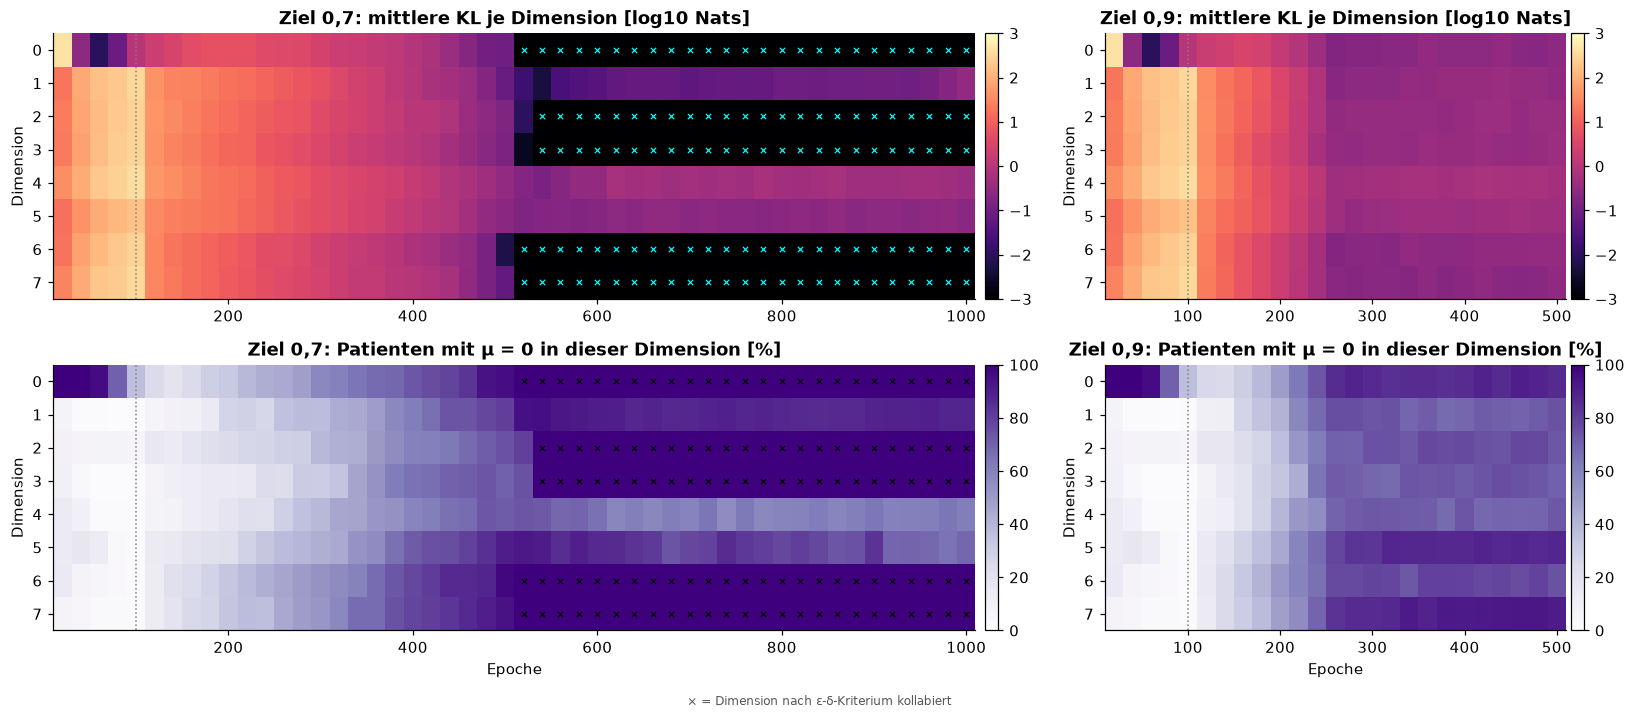

run,dim,collapse_epoch,reaktiviert,kl_warmup,kl_vorher,mu_0_vorher,eta2_krebs_vorher,eta2_sex_vorher,snapshot_vorher
"Ziel 0,7",6,520,False,275.686124,0.006178,0.977023,0.293571,0.013346,500
"Ziel 0,7",7,520,False,343.019248,0.063646,0.944056,0.523061,0.023083,500
"Ziel 0,7",0,520,False,1.047461,0.094775,0.954046,0.905935,0.417056,500
"Ziel 0,7",3,540,False,302.599096,0.146657,0.705295,0.786247,0.006089,500
"Ziel 0,7",2,540,False,279.319378,0.157491,0.746254,0.312981,0.012169,500
"Ziel 0,7",1,–,False,330.545753,0.075096,0.804196,0.407615,0.005629,500
"Ziel 0,7",5,–,False,172.556380,0.239363,0.903097,0.786889,0.001759,500
"Ziel 0,7",4,–,False,388.872038,0.298109,0.717283,0.648004,0.008357,500
"Ziel 0,9",0,–,False,1.047461,0.270132,0.862138,0.831683,0.428773,500
"Ziel 0,9",7,–,False,343.019248,0.274015,0.910090,0.769703,0.050151,500


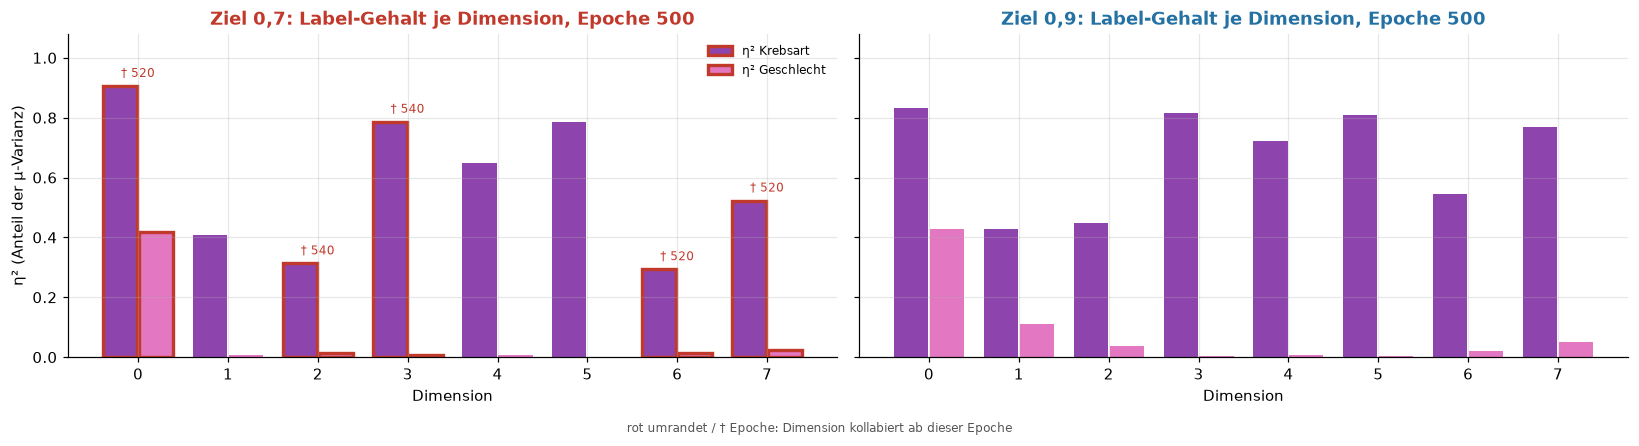

In [4]:
fig, axes = plt.subplots(2, NCOLS, figsize=(7.5 * NCOLS, 6.5), gridspec_kw=dict(width_ratios=WIDTHS))
for column_index, run in enumerate(COLLAPSE_RUNS):
    table = dimensions[dimensions.run.eq(run)]
    for row_index, (value, title, cmap, limits, transform) in enumerate((
            ("kl_mean", "mittlere KL je Dimension [log10 Nats]", "magma", (-3, 3), lambda v: np.log10(v.clip(lower=1e-3))),
            ("zero_fraction", "Patienten mit μ = 0 in dieser Dimension [%]", "Purples", (0, 100), lambda v: 100 * v))):
        ax = axes[row_index, column_index]
        grid = table.pivot(index="dim", columns="epoch", values=value)
        image = ax.imshow(transform(grid), aspect="auto", cmap=cmap, vmin=limits[0], vmax=limits[1],
                          extent=(grid.columns.min() - 10, grid.columns.max() + 10, 7.5, -.5), interpolation="nearest")
        collapsed = table.pivot(index="dim", columns="epoch", values="collapsed")
        ys, xs = np.nonzero(collapsed.to_numpy())
        ax.scatter(collapsed.columns.to_numpy()[xs], ys, marker="x", s=12, color="cyan" if row_index == 0 else "black", lw=.8)
        ax.axvline(REFERENCE_EPOCH, color="gray", ls=":", lw=1)
        ax.set(yticks=range(8), ylabel="Dimension", title=f"{run}: {title}", xlabel="Epoche" if row_index else None)
        ax.grid(False)
        fig.colorbar(image, ax=ax, pad=.01, fraction=.04)
fig.text(.5, .005, "× = Dimension nach ε-δ-Kriterium kollabiert", ha="center", fontsize=8, color="#555555")
fig.tight_layout(rect=(0, .02, 1, 1)); fig.savefig(COLLAPSE_ROOT / "kl_per_dimension.png", dpi=160); plt.show()

summary_rows = []
for run in COLLAPSE_RUNS:
    table = dimensions[dimensions.run.eq(run)]
    before = first_collapse.get(run, table.epoch.max() + 20) - 20
    at_before = table[table.epoch.eq(before)].set_index("dim")
    at_reference = table[table.epoch.eq(REFERENCE_EPOCH)].set_index("dim")
    for dim in range(8):
        collapsed_epochs = table[table.dim.eq(dim) & table.collapsed].epoch
        later = table[table.dim.eq(dim) & (table.epoch > collapsed_epochs.min())] if len(collapsed_epochs) else table.iloc[:0]
        summary_rows.append(dict(
            run=run, dim=dim, collapse_epoch=collapsed_epochs.min() if len(collapsed_epochs) else np.nan,
            reaktiviert=bool(len(later) and not later.collapsed.all()),
            kl_warmup=at_reference.loc[dim, "kl_mean"], kl_vorher=at_before.loc[dim, "kl_mean"],
            mu_0_vorher=at_before.loc[dim, "zero_fraction"],
            eta2_krebs_vorher=at_before.loc[dim, "eta2_cancer"], eta2_sex_vorher=at_before.loc[dim, "eta2_sex"],
            snapshot_vorher=before))
dimension_summary = pd.DataFrame(summary_rows).sort_values(["run", "collapse_epoch", "kl_vorher"], na_position="last")
dimension_summary.to_csv(COLLAPSE_ROOT / "dimension_summary.csv", index=False)
display(dimension_summary.style.format(precision=3, na_rep="–")
        .format({"collapse_epoch": "{:.0f}", "snapshot_vorher": "{:.0f}"}, na_rep="–").hide(axis="index"))

fig, axes = plt.subplots(1, NCOLS, figsize=(7.5 * NCOLS, 4), sharey=True)
for ax, run in zip(axes, COLLAPSE_RUNS):
    table = dimension_summary[dimension_summary.run.eq(run)].sort_values("dim")
    edge = ["#c0392b" if np.isfinite(e) else "none" for e in table.collapse_epoch]
    ax.bar(table.dim - .2, table.eta2_krebs_vorher, .38, color="#8e44ad", edgecolor=edge, lw=2.2, label="η² Krebsart")
    ax.bar(table.dim + .2, table.eta2_sex_vorher, .38, color="#e377c2", edgecolor=edge, lw=2.2, label="η² Geschlecht")
    for _, row in table[np.isfinite(table.collapse_epoch)].iterrows():
        ax.text(row.dim, max(row.eta2_krebs_vorher, row.eta2_sex_vorher) + .03, f"† {row.collapse_epoch:.0f}",
                ha="center", fontsize=8, color="#c0392b")
    ax.set(title=f"{run}: Label-Gehalt je Dimension, Epoche {table.snapshot_vorher.iloc[0]:.0f}",
           xlabel="Dimension", xticks=range(8), ylim=(0, 1.08))
    ax.title.set_color(RUN_COLORS[run])
axes[0].set_ylabel("η² (Anteil der μ-Varianz)")
axes[0].legend(fontsize=8, loc="upper right")
fig.text(.5, .005, "rot umrandet / † Epoche: Dimension kollabiert ab dieser Epoche", ha="center", fontsize=8, color="#555555")
fig.tight_layout(rect=(0, .03, 1, 1)); fig.savefig(COLLAPSE_ROOT / "label_content_per_dimension.png", dpi=160); plt.show()

### 8.3 Was passiert nach dem Collapse?

Nach dem ersten Collapse senkt der Controller β wieder, weil Trustworthiness unter das Zielband fällt.
Die Tabelle vergleicht fünf Zeitpunkte des kollabierenden Laufs: Ende Warm-up, letzter Snapshot vor dem Collapse,
erster Snapshot mit Collapse, schlechtester Trustworthiness-Wert danach und Laufende. Dazu der Patienten-Collapse
je Krebsart: Welche Krebsarten landen bei μ = 0, also beim Prior-Mittelwert?

run,moment,epoch,beta_over_d,rate,collapsed_dimensions,zero_entries,zero_patients,trustworthiness,auc_cancer,auc_sex,recon_valid
"Ziel 0,7",Ende Warm-up,100,0.00e+00,2093.65,0,6%,0%,0.959779,0.989250,0.832090,3.88e-04
"Ziel 0,7",letzter vor Collapse,500,2.79e-03,1.08,0,84%,14%,0.839719,0.716692,0.549049,8.40e-04
"Ziel 0,7",erster mit Collapse,520,4.09e-03,0.38,3,89%,27%,0.765035,0.585290,0.477421,9.25e-04
"Ziel 0,7",Tiefpunkt danach (T),900,1.90e-03,0.81,5,92%,49%,0.614108,0.634934,0.488874,8.87e-04
"Ziel 0,7",Laufende,1000,1.92e-03,0.93,5,90%,29%,0.745604,0.667499,0.515682,8.70e-04


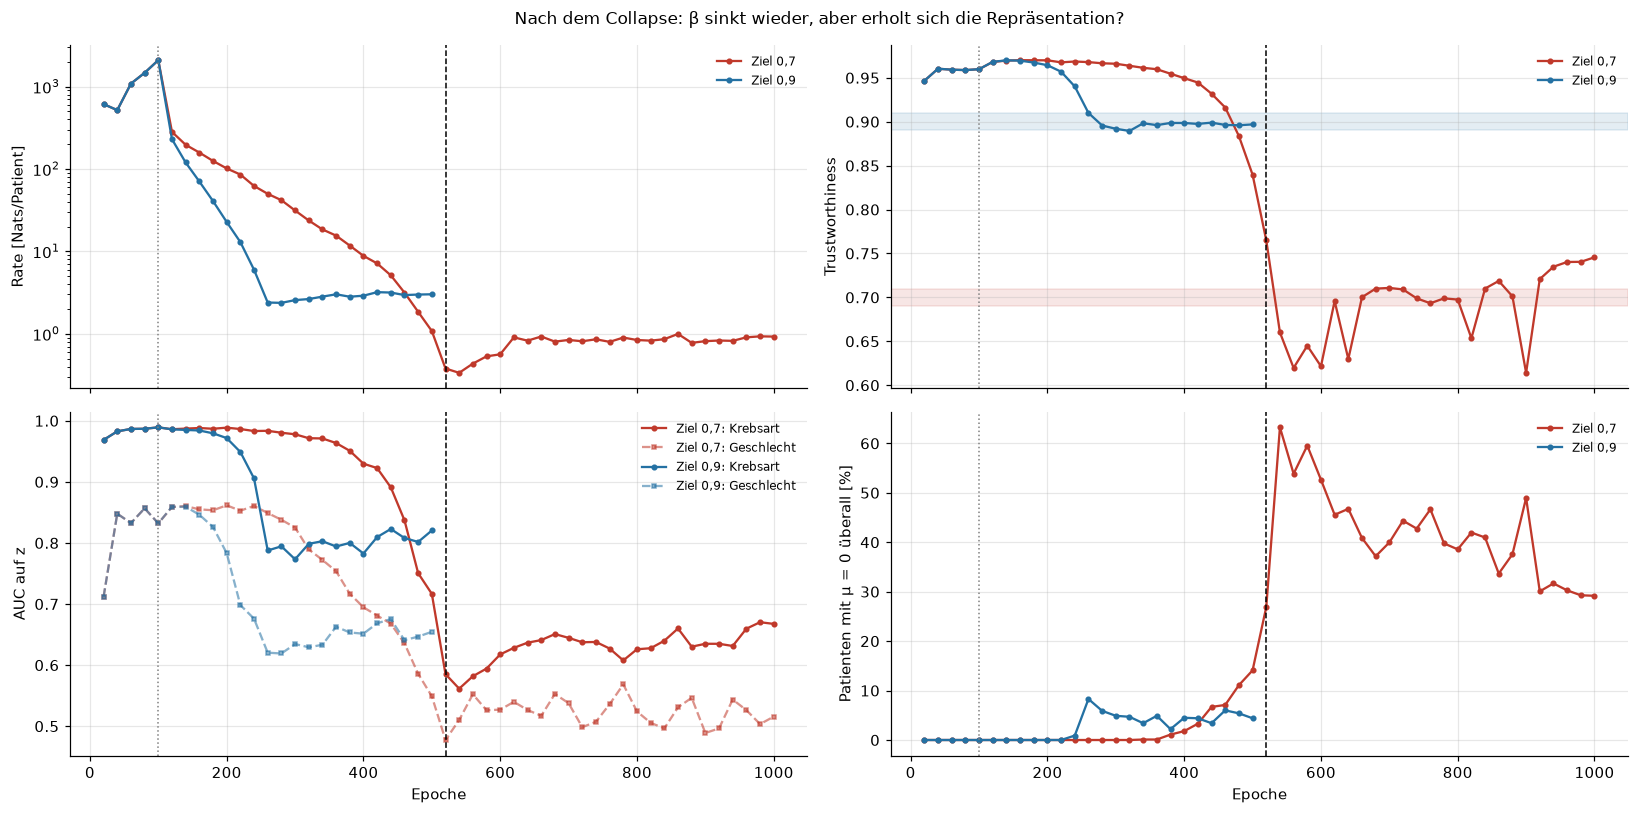

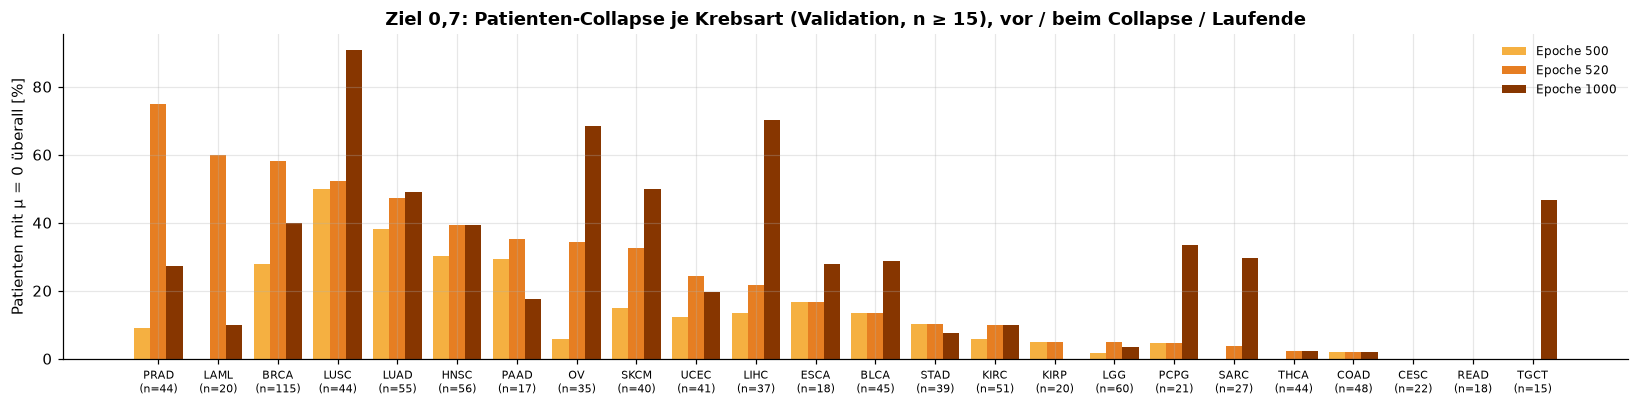

In [5]:
COLUMNS = ["epoch", "beta_over_d", "rate", "collapsed_dimensions", "zero_entries", "zero_patients", "trustworthiness",
           "auc_cancer", "auc_sex", "recon_valid"]
after_rows = []
for run in COLLAPSE_RUNS:
    if run not in first_collapse:
        continue
    group = snapshots[snapshots.run.eq(run)].sort_values("epoch").set_index("epoch", drop=False)
    onset = first_collapse[run]
    after = group[group.epoch >= onset]
    moments = {"Ende Warm-up": REFERENCE_EPOCH, "letzter vor Collapse": onset - 20, "erster mit Collapse": onset,
               "Tiefpunkt danach (T)": after.trustworthiness.idxmin(), "Laufende": group.epoch.max()}
    for moment, epoch in moments.items():
        after_rows.append(dict(run=run, moment=moment, **group.loc[epoch, COLUMNS].to_dict()))
after_collapse = pd.DataFrame(after_rows)
after_collapse.to_csv(COLLAPSE_ROOT / "after_collapse.csv", index=False)
display(after_collapse.style.format(precision=3).format({"epoch": "{:.0f}", "collapsed_dimensions": "{:.0f}",
        "beta_over_d": "{:.2e}", "rate": "{:.2f}", "recon_valid": "{:.2e}",
        "zero_entries": "{:.0%}", "zero_patients": "{:.0%}"}).hide(axis="index"))

fig, axes = plt.subplots(2, 2, figsize=(15, 7.5), sharex=True)
panels = [("rate", "Rate [Nats/Patient]", "log", None), ("trustworthiness", "Trustworthiness", None, None),
          ("auc_cancer", "AUC auf z", None, "auc_sex"), ("zero_patients", "Patienten mit μ = 0 überall [%]", None, None)]
for ax, (column, ylabel, scale, second) in zip(axes.flat, panels):
    for run, group in snapshots.groupby("run"):
        group = group.sort_values("epoch")
        values = 100 * group[column] if column == "zero_patients" else group[column]
        ax.plot(group.epoch, values, "o-", ms=3, color=RUN_COLORS[run], label=run if not second else f"{run}: Krebsart")
        if second:
            ax.plot(group.epoch, group[second], "s--", ms=3, color=RUN_COLORS[run], alpha=.55, label=f"{run}: Geschlecht")
    if column == "trustworthiness":
        for target, run in ((.7, "Ziel 0,7"), (.9, "Ziel 0,9")):
            ax.axhspan(target - .01, target + .01, color=RUN_COLORS[run], alpha=.12)
    for run, epoch in first_collapse.items():
        ax.axvline(epoch, color="black", ls="--", lw=1)
    ax.axvline(REFERENCE_EPOCH, color="gray", ls=":", lw=1)
    ax.set(ylabel=ylabel, yscale=scale or "linear")
    ax.legend(fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("Epoche")
fig.suptitle("Nach dem Collapse: β sinkt wieder, aber erholt sich die Repräsentation?", fontsize=11)
fig.tight_layout(); fig.savefig(COLLAPSE_ROOT / "after_collapse.png", dpi=160); plt.show()

# Patienten-Collapse je Krebsart (Validation) im kollabierenden Lauf
run = "Ziel 0,7"
folder = run_folder(run)
labels = pd.read_parquet(folder / "epoch_snapshots" / "labels_valid.parquet")
labels.index = labels.index.astype(str)
by_type = {}
for epoch in (first_collapse[run] - 20, first_collapse[run], snapshots[snapshots.run.eq(run)].epoch.max()):
    with np.load(folder / "epoch_snapshots" / f"epoch_{epoch:05d}_valid.npz") as saved:
        ids, mu = saved["sample_ids"].astype(str), saved["mu"]
    by_type[f"Epoche {epoch}"] = pd.Series((mu == 0).all(1), index=ids).groupby(labels.loc[ids].CANCER_TYPE_ACRONYM.to_numpy()).mean()
by_type = pd.DataFrame(by_type)
by_type["n"] = labels.CANCER_TYPE_ACRONYM.value_counts()
by_type = by_type[by_type.n >= 15].sort_values(by_type.columns[1], ascending=False)
by_type.to_csv(COLLAPSE_ROOT / "patient_collapse_by_cancer.csv")
fig, ax = plt.subplots(figsize=(15, 3.8))
positions = np.arange(len(by_type))
for offset, (column, color) in zip((-.27, 0, .27), zip(by_type.columns[:3], ("#f5b041", "#e67e22", "#873600"))):
    ax.bar(positions + offset, 100 * by_type[column], .27, color=color, label=column)
ax.set(xticks=positions, ylabel="Patienten mit μ = 0 überall [%]",
       title=f"{run}: Patienten-Collapse je Krebsart (Validation, n ≥ 15), vor / beim Collapse / Laufende")
ax.set_xticklabels([f"{t}\n(n={n})" for t, n in zip(by_type.index, by_type.n)], fontsize=7)
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(COLLAPSE_ROOT / "patient_collapse_by_cancer.png", dpi=160); plt.show()

### 8.4 Bei welchem Trustworthiness- bzw. MRRE-false-Wert liegt der Collapse?

**Annealing-Lauf:** Der Controller misst Trustworthiness alle 5 Epochen, Collapse ist nur an den Snapshots
(alle 20 Epochen) bestimmbar. Der Collapse liegt also zwischen zwei Snapshots; angegeben werden die Werte am letzten
Snapshot ohne und am ersten mit Collapse sowie die Controller-Messungen dazwischen. MRRE false ist dort wegen der
Patienten bei μ = 0 nicht messbar.

**β-Sweep (24 Trajektorien, 240 Läufe):** Pro Trajektorie (d, Seed) der Wert beim größten β ohne und beim kleinsten β
mit kollabierter Dimension, gemessen auf dem Test-μ (alle Testpatienten, k = 20). Im Plot ist jede Trajektorie eine
Linie von „ohne“ nach „mit Collapse“. Zusätzlich eine logistische Regression P(mindestens eine Dimension kollabiert | Metrik)
über alle Läufe: der Metrikwert bei 50 % und bei 5 % Collapse-Wahrscheinlichkeit. Sweep und Annealing nutzen dieselbe
Metrikdefinition, aber andere Patienten und Stichprobengrößen; die Werte sind vergleichbar, nicht identisch.

quelle,metric,ohne_collapse,mit_collapse,controller_T_dazwischen,ohne_q10_q90,mit_q10_q90,logit_50,logit_5
"Annealing Ziel 0,7",trustworthiness,0.840,0.765,"Ep. 505: 0.832, Ep. 510: 0.813, Ep. 515: 0.786, Ep. 520: 0.765",,,,
"Annealing Ziel 0,7",mrre_false,,,,,,,
"Annealing Ziel 0,7",lcmc,,,,,,,
Sweep (24 Trajektorien),trustworthiness,0.934,0.868,,0.813 – 0.955,0.544 – 0.956,0.803,0.992
Sweep (24 Trajektorien),mrre_false,0.931,0.853,,0.804 – 0.953,0.488 – 0.954,0.799,0.989
Sweep (24 Trajektorien),lcmc,0.371,0.240,,0.153 – 0.442,0.040 – 0.445,0.211,0.447


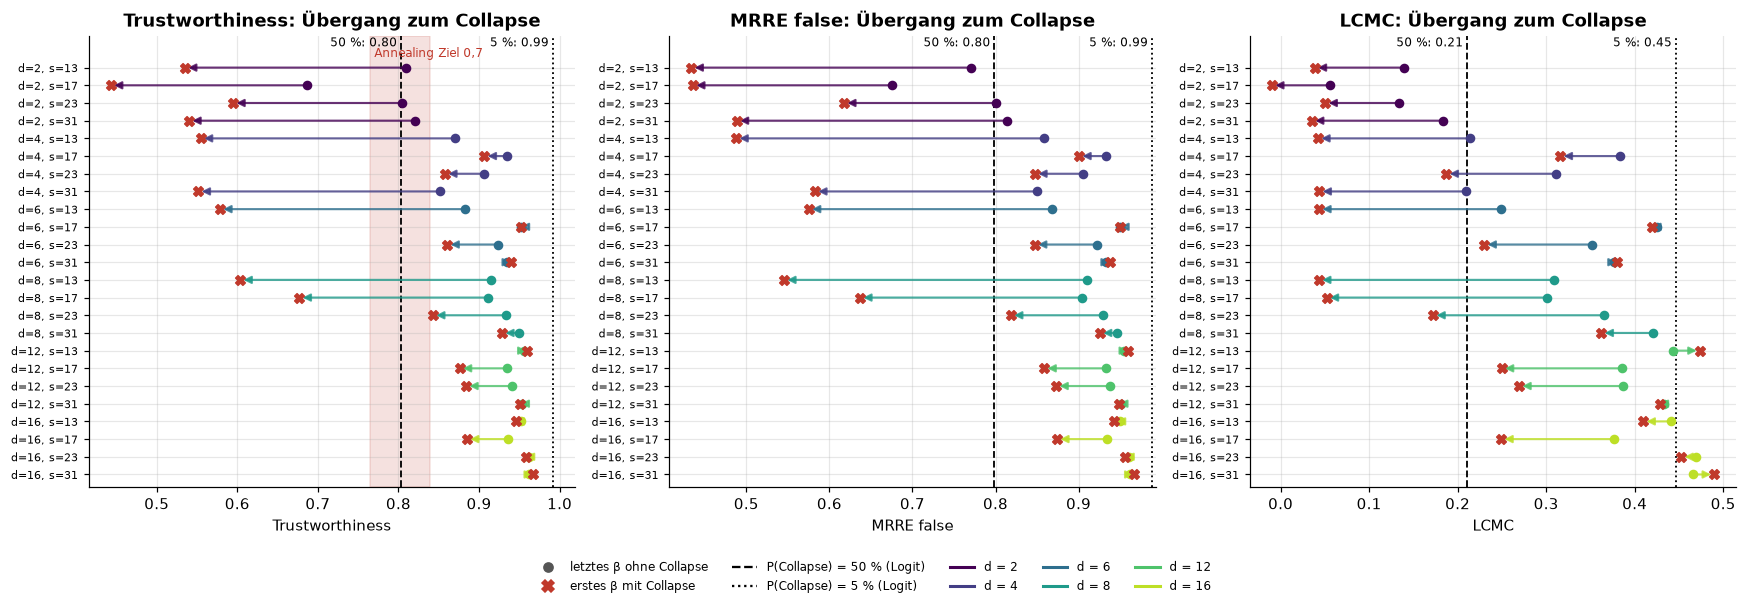

In [6]:
rows = []
for run in COLLAPSE_RUNS:
    if run not in first_collapse:
        continue
    onset = first_collapse[run]
    group = snapshots[snapshots.run.eq(run)].set_index("epoch")
    controller = pd.read_csv(run_folder(run) / "controller_log.csv")
    between = controller[(controller.epoch > onset - 20) & (controller.epoch <= onset)].dropna(subset=["metric_value"])
    for metric in ("trustworthiness", "mrre_false", "lcmc"):
        rows.append(dict(quelle=f"Annealing {run}", metric=metric, ohne_collapse=group.loc[onset - 20, metric],
                         mit_collapse=group.loc[onset, metric],
                         controller_T_dazwischen=", ".join(f"Ep. {e}: {v:.3f}" for e, v in zip(between.epoch, between.metric_value))
                         if metric == "trustworthiness" else ""))

SWEEP = PROJECT_ROOT / "beta_vae_experiments/new_results_2026-09-29/biology_breakpoints_2026_09_29/experiment_metrics.csv"
sweep = pd.read_csv(SWEEP)
COLLAPSED = "posterior_collapsed_dimensions_count_eps_0p01_delta_0p01"
SWEEP_METRICS = {"trustworthiness": ("geometry_mu_trustworthiness_zadu_k20", "Trustworthiness"),
                 "mrre_false": ("geometry_mu_mrre_false_zadu_k20", "MRRE false"),
                 "lcmc": ("geometry_mu_lcmc_zadu_k20", "LCMC")}
transitions = []
for (latent_dim, seed), group in sweep.sort_values("beta").groupby(["latent_dim", "seed"]):
    collapsed = group[group[COLLAPSED] > 0]
    if collapsed.empty:
        continue
    onset = collapsed.iloc[0]
    clean = group[(group.beta < onset.beta) & group[COLLAPSED].eq(0)]
    if clean.empty:
        continue
    last_clean = clean.iloc[-1]
    for metric, (column, _) in SWEEP_METRICS.items():
        transitions.append(dict(latent_dim=latent_dim, seed=seed, metric=metric, ohne_collapse=last_clean[column],
                                mit_collapse=onset[column], dims_beim_collapse=onset[COLLAPSED]))
transitions = pd.DataFrame(transitions)
transitions.to_csv(COLLAPSE_ROOT / "sweep_collapse_transitions.csv", index=False)

for metric, (column, _) in SWEEP_METRICS.items():
    part = transitions[transitions.metric.eq(metric)]
    data = sweep[[column, COLLAPSED]].dropna()
    model = LogisticRegression(C=1e6, max_iter=1000).fit(data[[column]], data[COLLAPSED] > 0)
    slope, intercept = model.coef_[0, 0], model.intercept_[0]
    rows.append(dict(quelle=f"Sweep ({len(part)} Trajektorien)", metric=metric,
                     ohne_collapse=part.ohne_collapse.median(), mit_collapse=part.mit_collapse.median(),
                     ohne_q10_q90=f"{part.ohne_collapse.quantile(.1):.3f} – {part.ohne_collapse.quantile(.9):.3f}",
                     mit_q10_q90=f"{part.mit_collapse.quantile(.1):.3f} – {part.mit_collapse.quantile(.9):.3f}",
                     logit_50=-intercept / slope, logit_5=(np.log(.05 / .95) - intercept) / slope))
collapse_values = pd.DataFrame(rows)
collapse_values.to_csv(COLLAPSE_ROOT / "collapse_values.csv", index=False)
display(collapse_values.style.format(precision=3, na_rep="").hide(axis="index"))

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
dim_colors = dict(zip(sorted(sweep.latent_dim.unique()), plt.cm.viridis(np.linspace(0, .9, sweep.latent_dim.nunique()))))
for ax, (metric, (column, label)) in zip(axes, SWEEP_METRICS.items()):
    part = transitions[transitions.metric.eq(metric)].sort_values(["latent_dim", "seed"]).reset_index(drop=True)
    for y, row in part.iterrows():
        color = dim_colors[row.latent_dim]
        ax.annotate("", xy=(row.mit_collapse, y), xytext=(row.ohne_collapse, y),
                    arrowprops=dict(arrowstyle="-|>", color=color, lw=1.4, alpha=.8))
        ax.scatter(row.ohne_collapse, y, s=28, color=color, zorder=3)
        ax.scatter(row.mit_collapse, y, s=40, marker="X", color="#c0392b", zorder=3)
    value = collapse_values[collapse_values.metric.eq(metric) & collapse_values.quelle.str.startswith("Sweep")].iloc[0]
    ax.axvline(value.logit_50, color="black", ls="--", lw=1.2)
    ax.axvline(value.logit_5, color="black", ls=":", lw=1.2)
    ax.text(value.logit_50, -1.2, f"50 %: {value.logit_50:.2f} ", ha="right", fontsize=8)
    ax.text(value.logit_5, -1.2, f"5 %: {value.logit_5:.2f} ", ha="right", fontsize=8)
    for run in first_collapse.index:
        annealing = collapse_values[collapse_values.metric.eq(metric) & collapse_values.quelle.eq(f"Annealing {run}")].iloc[0]
        if np.isfinite(annealing.ohne_collapse):
            ax.axvspan(annealing.mit_collapse, annealing.ohne_collapse, color=RUN_COLORS[run], alpha=.15)
            ax.text(annealing.mit_collapse, -.6, f" Annealing {run}", color=RUN_COLORS[run], fontsize=8, ha="left")
    ax.set(yticks=range(len(part)), yticklabels=[f"d={d}, s={s}" for d, s in zip(part.latent_dim, part.seed)],
           ylim=(len(part) - .3, -1.8), xlabel=label, title=f"{label}: Übergang zum Collapse")
    ax.tick_params(axis="y", labelsize=7)
legend = [Line2D([], [], ls="", marker="o", color="#555555", label="letztes β ohne Collapse"),
          Line2D([], [], ls="", marker="X", color="#c0392b", ms=8, label="erstes β mit Collapse"),
          Line2D([], [], ls="--", color="black", label="P(Collapse) = 50 % (Logit)"),
          Line2D([], [], ls=":", color="black", label="P(Collapse) = 5 % (Logit)")]
legend += [Line2D([], [], color=c, lw=2, label=f"d = {d}") for d, c in dim_colors.items()]
fig.legend(handles=legend, loc="lower center", ncol=5, fontsize=8)
fig.tight_layout(rect=(0, .08, 1, 1)); fig.savefig(COLLAPSE_ROOT / "collapse_threshold.png", dpi=160); plt.show()

### 8.4b Vergleich mit Rate und Distortion

Dieselbe Frage für die Rate-Distortion-Größen: Rate (Gesamt-KL), Rate pro Dimension und Distortion (Rekonstruktions-MSE, Test).
Oben die Mediane beim letzten β ohne und beim ersten β mit Collapse je d, unten wie gut jedes Signal kollabierte von nicht
kollabierten Sweep-Läufen trennt (ROC-AUC, 1 = perfekt; gesamt und innerhalb eines d). Das ist eine Collapse-Diagnose,
keine Downstream-AUC.

,gesamt,d=2,d=4,d=6,d=8,d=12,d=16
signal,,,,,,,
Trustworthiness,0.894,1.000,0.980,0.940,0.994,0.936,0.898
MRRE false,0.895,1.000,0.990,0.940,0.994,0.939,0.900
Rate,0.937,1.000,0.977,0.943,0.981,0.933,0.898
Rate/d,0.957,1.000,0.977,0.943,0.981,0.933,0.898
Distortion (MSE),0.915,1.000,0.987,0.943,0.984,0.923,0.898


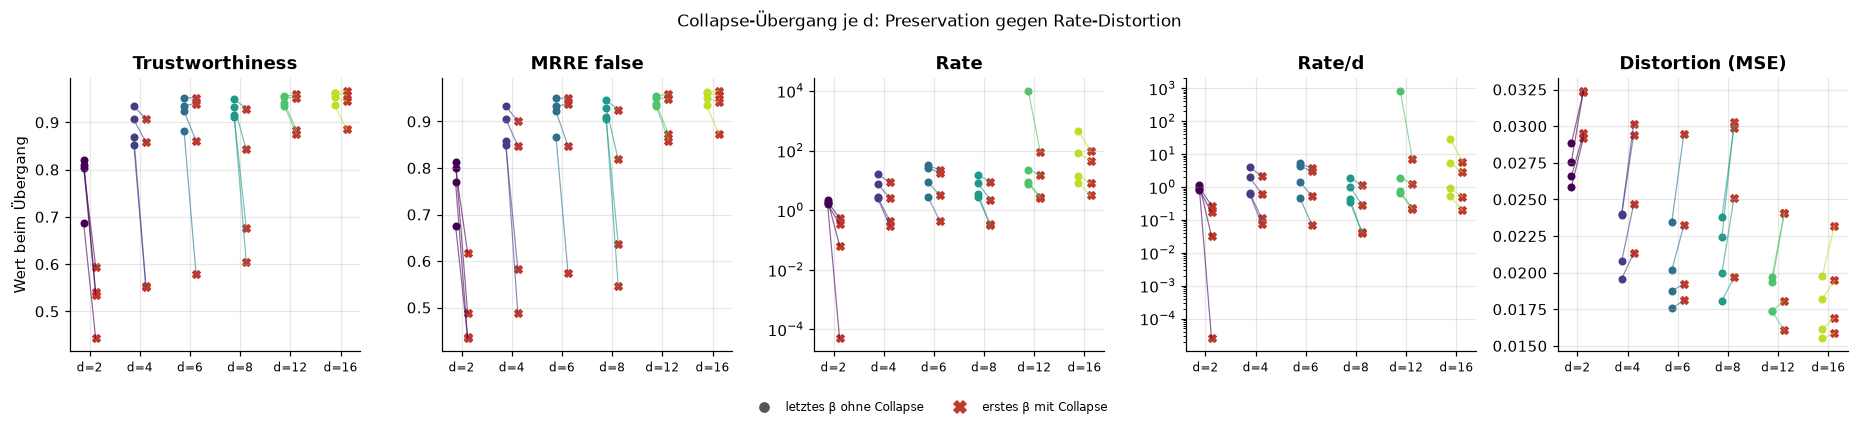

In [7]:
from sklearn.metrics import roc_auc_score

sweep["rate"] = sweep.posterior_conditional_kl_total_mean
sweep["rate_per_dim"] = sweep.rate / sweep.latent_dim
RD_SIGNALS = {"Trustworthiness": ("geometry_mu_trustworthiness_zadu_k20", +1), "MRRE false": ("geometry_mu_mrre_false_zadu_k20", +1),
              "Rate": ("rate", +1), "Rate/d": ("rate_per_dim", +1), "Distortion (MSE)": ("recon_test_mse", -1)}
rows = []
for (latent_dim, seed), group in sweep.sort_values("beta").groupby(["latent_dim", "seed"]):
    collapsed = group[group[COLLAPSED] > 0]
    if collapsed.empty:
        continue
    onset = collapsed.iloc[0]
    clean = group[(group.beta < onset.beta) & group[COLLAPSED].eq(0)]
    if clean.empty:
        continue
    for label, (column, _) in RD_SIGNALS.items():
        rows.append(dict(d=latent_dim, seed=seed, signal=label, ohne=clean.iloc[-1][column], mit=onset[column]))
rd_transitions = pd.DataFrame(rows)
rd_table = rd_transitions.groupby(["signal", "d"])[["ohne", "mit"]].median().unstack("signal").swaplevel(axis=1)
rd_table = rd_table[[(s, c) for s in RD_SIGNALS for c in ("ohne", "mit")]]
rd_table.to_csv(COLLAPSE_ROOT / "rate_distortion_collapse_values.csv")
display(rd_table.style.format(precision=3).set_caption("Median je d: letztes β ohne / erstes β mit Collapse"))

separation = []
for label, (column, direction) in RD_SIGNALS.items():
    row = dict(signal=label, gesamt=roc_auc_score(sweep[COLLAPSED] > 0, -direction * sweep[column]))
    for latent_dim, group in sweep.groupby("latent_dim"):
        row[f"d={latent_dim}"] = roc_auc_score(group[COLLAPSED] > 0, -direction * group[column])
    separation.append(row)
separation = pd.DataFrame(separation).set_index("signal")
separation.to_csv(COLLAPSE_ROOT / "collapse_separation_auc.csv")
display(separation.style.format(precision=3).background_gradient(cmap="Greens", vmin=.85, vmax=1)
        .set_caption("Trennung kollabiert / nicht kollabiert (ROC-AUC)"))

fig, axes = plt.subplots(1, len(RD_SIGNALS), figsize=(17, 3.8))
for ax, (label, (column, _)) in zip(axes, RD_SIGNALS.items()):
    part = rd_transitions[rd_transitions.signal.eq(label)]
    for latent_dim, group in part.groupby("d"):
        x = np.full(len(group), list(dim_colors).index(latent_dim))
        ax.scatter(x - .12, group.ohne, s=18, color=dim_colors[latent_dim])
        ax.scatter(x + .12, group.mit, s=24, marker="X", color="#c0392b")
        for xi, a, b in zip(x, group.ohne, group.mit):
            ax.plot([xi - .12, xi + .12], [a, b], color=dim_colors[latent_dim], lw=.8, alpha=.6)
    ax.set(xticks=range(len(dim_colors)), xticklabels=[f"d={d}" for d in dim_colors], title=label,
           yscale="log" if label.startswith("Rate") else "linear")
    ax.tick_params(axis="x", labelsize=8)
axes[0].set_ylabel("Wert beim Übergang")
fig.legend(handles=legend[:2], loc="lower center", ncol=2, fontsize=8)
fig.suptitle("Collapse-Übergang je d: Preservation gegen Rate-Distortion", fontsize=11)
fig.tight_layout(rect=(0, .07, 1, 1)); fig.savefig(COLLAPSE_ROOT / "collapse_rate_distortion.png", dpi=160); plt.show()

### 8.6 Rate gegen Trustworthiness, mit Collapse nach zwei Kriterien

Jeder Punkt ist ein Snapshot (alle 20 Epochen), verbunden in zeitlicher Reihenfolge; die Farbe zeigt, wie viele der
8 Dimensionen kollabiert bzw. inaktiv sind. Im Hintergrund (Quadrate): die d = 8-Läufe des β-Sweeps (Test-μ, alle Testpatienten); vollständig kollabierte
Sweep-Läufe mit Rate < 0,1 liegen außerhalb des gezeigten Bereichs.
Die Annealing-Trustworthiness stammt vom Validierungs-Subset (800 Patienten); beide sind vergleichbar, nicht identisch.

Zwei gängige Definitionen, wann eine latente Dimension „weg“ ist:

- **ε-δ-Collapse (links, unsere Definition):** Die Posterior entspricht für fast alle Patienten dem Prior,
  KL(q(z_j|x) ‖ N(0,1)) < 0,01 Nats bei mindestens 99 % der Patienten. Misst: trägt die Dimension für einzelne Patienten Information?
- **Active Units (rechts; Burda et al. 2016, `compute_active_units` im Projekt):** Eine Dimension ist aktiv, wenn
  Var_x(μ_j) > 0,01, also wenn sich der Mittelwert zwischen Patienten unterscheidet. Misst: unterscheidet die Dimension Patienten?

Wegen der logvar-Klemme (σ ≥ 1,005) hängt die KL hier praktisch nur an μ; beide Kriterien sind deshalb eng verwandt.
Sie können trotzdem auseinanderfallen: eine Dimension mit konstantem μ ≠ 0 ist nach Active Units inaktiv, nach ε-δ nicht kollabiert.

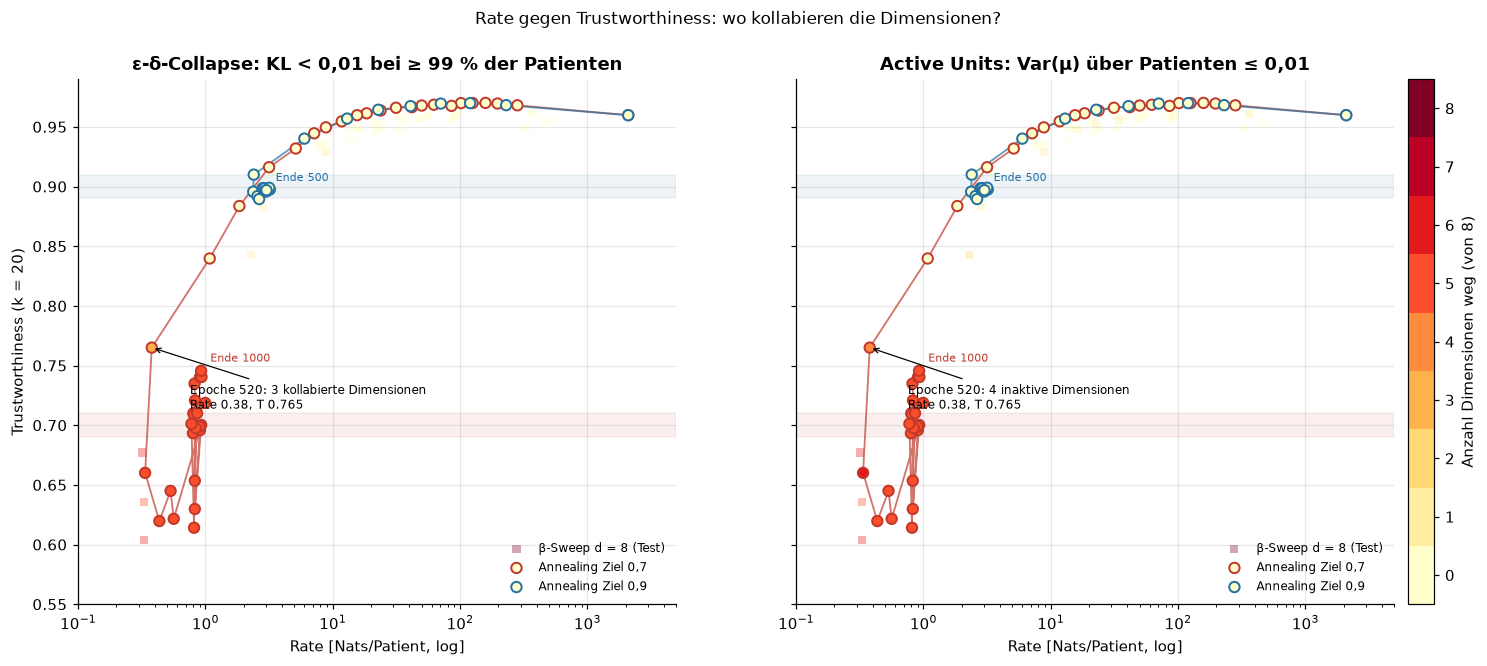

run,epoch,rate,trustworthiness,collapsed_dimensions,inactive_units
"Ziel 0,7",20,612.874542,0.946572,0,1
"Ziel 0,7",40,518.150099,0.960309,0,1
"Ziel 0,7",60,1086.735268,0.959247,0,1
"Ziel 0,7",500,1.081315,0.839719,0,0
"Ziel 0,7",520,0.379047,0.765035,3,4
"Ziel 0,7",540,0.336096,0.660088,5,6
"Ziel 0,9",20,612.874542,0.946572,0,1
"Ziel 0,9",40,518.150099,0.960309,0,1
"Ziel 0,9",60,1086.735268,0.959247,0,1
"Ziel 0,9",500,3.017633,0.896944,0,0


In [8]:
units = (dimensions.assign(active=dimensions.mu_std ** 2 > 0.01).groupby(["run", "epoch"]).active.sum()
         .rename("active_units").reset_index())
rate_tw = snapshots.merge(units, on=["run", "epoch"])
rate_tw["inactive_units"] = 8 - rate_tw.active_units
sweep8 = sweep[sweep.latent_dim.eq(8)].assign(inactive_units=lambda f: 8 - f.posterior_active_units_count_eps_0p01)
CRITERIA = (("collapsed_dimensions", COLLAPSED, "ε-δ-Collapse: KL < 0,01 bei ≥ 99 % der Patienten", "kollabierte Dimensionen"),
            ("inactive_units", "inactive_units", "Active Units: Var(μ) über Patienten ≤ 0,01", "inaktive Dimensionen"))
cmap = plt.get_cmap("YlOrRd", 9)
fig, axes = plt.subplots(1, 2, figsize=(16, 6.2), sharey=True)
for ax, (column, sweep_column, title, label) in zip(axes, CRITERIA):
    ax.scatter(sweep8.rate, sweep8.geometry_mu_trustworthiness_zadu_k20, c=sweep8[sweep_column], cmap=cmap,
               vmin=-.5, vmax=8.5, marker="s", s=28, alpha=.35, edgecolor="none", label="β-Sweep d = 8 (Test)")
    for run, group in rate_tw.groupby("run", sort=False):
        group = group[group.epoch >= REFERENCE_EPOCH].sort_values("epoch")
        ax.plot(group.rate, group.trustworthiness, "-", color=RUN_COLORS[run], lw=1.2, alpha=.7)
        points = ax.scatter(group.rate, group.trustworthiness, c=group[column], cmap=cmap, vmin=-.5, vmax=8.5,
                            s=46, edgecolor=RUN_COLORS[run], linewidth=1.3, zorder=3, label=f"Annealing {run}")
        onset = group[group[column] > 0]
        if len(onset):
            first = onset.iloc[0]
            ax.annotate(f"Epoche {first.epoch:.0f}: {first[column]:.0f} {label}\nRate {first.rate:.2f}, T {first.trustworthiness:.3f}",
                        (first.rate, first.trustworthiness), xytext=(25, -40), textcoords="offset points", fontsize=8,
                        arrowprops=dict(arrowstyle="->", color="black", lw=.8))
        end = group.iloc[-1]
        ax.annotate(f"Ende {end.epoch:.0f}", (end.rate, end.trustworthiness), xytext=(6, 6), textcoords="offset points",
                    fontsize=7, color=RUN_COLORS[run])
    for target, run in zip((.7, .9), RUN_COLORS):
        ax.axhspan(target - .01, target + .01, color=RUN_COLORS[run], alpha=.08)
    ax.set(xscale="log", xlabel="Rate [Nats/Patient, log]", title=title, xlim=(.1, 5e3), ylim=(.55, .99))
    ax.legend(fontsize=8, loc="lower right")
axes[0].set_ylabel("Trustworthiness (k = 20)")
colorbar = fig.colorbar(points, ax=axes, ticks=range(9), pad=.01, fraction=.025)
colorbar.set_label("Anzahl Dimensionen weg (von 8)")
fig.suptitle("Rate gegen Trustworthiness: wo kollabieren die Dimensionen?", fontsize=11)
fig.savefig(COLLAPSE_ROOT / "rate_vs_trustworthiness_collapse.png", dpi=160, bbox_inches="tight"); plt.show()

agreement = rate_tw[["run", "epoch", "rate", "trustworthiness", "collapsed_dimensions", "inactive_units"]]
display(agreement[agreement.collapsed_dimensions.ne(agreement.inactive_units)
                  | agreement.epoch.isin(first_collapse.reindex(agreement.run).to_numpy() - 20)]
        .style.format(precision=3).format({"epoch": "{:.0f}"}).hide(axis="index")
        .set_caption("Snapshots, in denen die Kriterien abweichen, und der letzte Snapshot vor dem Collapse"))

### 8.5 Einordnung

**Reihenfolge der Zerstörung (Ziel 0,7, d = 8, Seed 17).** Zuerst steigt der Rekonstruktionsfehler (2 % ab Epoche 120,
β/d ≈ 2·10⁻⁶; 20 % ab Epoche 320). Als erstes Downstream-Signal fällt **Geschlecht** (5 % ab Epoche 320, 20 % ab 460),
dann Cohesiveness (5 % ab 340), dann **Krebsart** (5 % ab 400, 20 % ab 480), dann **Trustworthiness** (5 % ab 480, 20 % ab 520)
und zuletzt die **Dimensionen** (erste drei bei Epoche 520, β/d ≈ 4·10⁻³; fünf ab 540). LCMC und MRRE false sind ab Epoche 380
wegen Patienten bei μ = 0 nicht mehr messbar; LCMC hatte bis dahin 5 % verloren, MRRE false weniger als 2 %.
Im Lauf mit Ziel 0,9 ist die Reihenfolge gleich (Rekonstruktion → Geschlecht → LCMC/Cohesiveness/Krebsart → Trustworthiness),
er stoppt aber vor dem Dimensions-Collapse. Trustworthiness ist damit ein **spätes** Signal: Wenn sie 5 % verloren hat,
sind Geschlecht und Krebsart schon um 5 bis 20 % gefallen.

**Welche Dimensionen kollabieren.** Zuerst Dimension 0, 6 und 7, dann 2 und 3. Dimension 0 war die am stärksten
label-tragende Achse (η² Krebsart 0,91, Geschlecht 0,42; die einzige Achse mit nennenswertem Geschlechtsanteil).
Der Collapse opfert also **nicht** bevorzugt uninformative Achsen; mit Dimension 0 verschwindet die Geschlechtsinformation,
und die Geschlechts-AUC fällt auf Zufallsniveau (≈ 0,5). Keine kollabierte Dimension wird später wieder aktiv.

**Nach dem Collapse.** Der Controller senkt β/d von 4,5·10⁻³ auf 1,9·10⁻³ (−58 %). Die Rate erholt sich nur von 0,34 auf
≈ 0,9 Nats, die fünf Dimensionen bleiben kollabiert, Trustworthiness erreicht 0,75 (Warm-up 0,96), die Krebs-AUC 0,67
(Warm-up 0,99), Geschlecht bleibt bei ≈ 0,5. Der Anteil der Patienten mit μ = 0 fällt von 63 % auf 29 %; die übrigen drei
Dimensionen verteilen also einen Teil der Information neu, die verlorenen Achsen kommen aber nicht zurück. Das passt zum
Mechanismus: μ-Koordinaten bei 0 bekommen durch die Abschneidung in Varix keinen Gradienten mehr.
Auch der stabile Lauf mit Ziel 0,9 hat ≈ 80 % μ-Einträge bei 0 und 4–8 % Patienten vollständig bei μ = 0:
**Patienten-Collapse tritt vor dem Dimensions-Collapse auf** und betrifft je Krebsart unterschiedlich viele Patienten.

**Bei welchem Wert.** Im Annealing-Lauf liegt der Collapse zwischen Trustworthiness 0,84 und 0,77. Im Sweep hängt die Schwelle
stark von d ab: für d = 8 bleibt jede Trajektorie mit T ≥ 0,93 intakt, unter ≈ 0,91 ist überall eine Dimension weg;
für d ≥ 12 kollabieren überzählige Dimensionen schon bei T ≈ 0,95, ohne dass T sinkt. Innerhalb eines d trennen
Trustworthiness, Rate und Distortion Collapse gleich gut (ROC-AUC 0,90–1,0); über alle d hinweg ist Rate/d am besten.
Für reine Collapse-Vermeidung ist die KL je Dimension, also die Collapse-Definition selbst, das direkteste Signal.

## 9. Topologie-Pipeline auf dem Collapse-Verlauf

Dieselben Snapshots, ausgewertet mit der Topologie-Pipeline des Projekts (`metrics/topology`), auf dem festen
Controller-Subset (800 Validierungspatienten; X und μ paarweise ausgerichtet):

- **X↔μ-Vergleich (durchmesser-normiert):** Ripser auf D/max(D) je Raum (`RIPSER_CONFIG`: maxdim = 1, coeff = 2, thresh = ∞),
  dann Wasserstein W1 (persim) und Bottleneck (GUDHI) für H0 und H1 (`compute_persistence_diagrams_h0_h1`,
  `compute_normalized_wasserstein_h0_h1`, `compute_normalized_bottleneck_h0_h1`). Kleiner = Form besser erhalten.
  Diese Normierung entfernt die Kontraktion absichtlich und misst nur die relative Form.
- **Deskriptoren von μ:** Persistenz-Entropie H0/H1 (`compute_persistence_entropy`) und Balkenstatistik
  (`summarize_persistence_diagrams`); X dient als Referenz.
- **Feste Skala (Rauscheinheiten):** Ripser auf μ / 2,01 (2σ bei der logvar-Klemme), thresh = 3. Gezählt werden die
  H0-Komponenten und lebenden H1-Schleifen bei t = 1. Eine Komponente bei t = 1 heißt: Patienten, die mehr als
  2σ Rauschen voneinander entfernt sind. Das misst Unterscheidbarkeit in z, nicht Form.

Patienten mit μ = 0 sind Punkte im Abstand 0; sie verschmelzen bei Filtrationswert 0 (Balken der Länge 0) und
zählen wie ein Punkt. Die Pipeline lässt Balken der Länge 0 in Zusammenfassungen weg.

In [9]:
from sklearn.metrics import pairwise_distances
from ripser import ripser
from beta_vae_experiments.metrics.topology.preservation import (
    RIPSER_CONFIG, compute_persistence_diagrams_h0_h1, compute_normalized_wasserstein_h0_h1,
    compute_normalized_bottleneck_h0_h1)
from beta_vae_experiments.metrics.topology.latent_descriptor import compute_persistence_entropy, summarize_persistence_diagrams

NOISE_UNIT = 2 * np.exp(0.5 * 0.01)
FS_THRESH, FS_T = 3.0, 1.0
TOPOLOGY_ROOT = COLLAPSE_ROOT / "topology"
TOPOLOGY_ROOT.mkdir(exist_ok=True)
topology_cache = TOPOLOGY_ROOT / "topology_snapshots.csv"
topology = pd.read_csv(topology_cache) if topology_cache.exists() else pd.DataFrame(columns=["run"])
missing_runs = [run for run in COLLAPSE_RUNS if run not in set(topology.run)]
if missing_runs:  # nur neue Läufe berechnen
    topology_rows = []
    for run in missing_runs:
        folder = run_folder(run)
        with np.load(folder / "controller_validation_reference.npz") as reference:
            x_reference, reference_ids = reference["x"].astype(np.float64), reference["sample_ids"].astype(str)
        dx = pairwise_distances(x_reference)
        input_diagrams = ripser(dx / dx.max(), **RIPSER_CONFIG)["dgms"]
        for path in sorted((folder / "epoch_snapshots").glob("epoch_*_valid.npz")):
            epoch = int(path.stem.split("_")[1])
            with np.load(path) as saved:
                positions = pd.Index(saved["sample_ids"].astype(str)).get_indexer(reference_ids)
                mu = saved["mu"][positions].astype(np.float64)
            row = dict(run=run, epoch=epoch, distinct_mu=len(np.unique(mu, axis=0)))
            dm = pairwise_distances(mu)
            if dm.max() > 1e-12:
                diagrams = compute_persistence_diagrams_h0_h1(dx, dm, dx.max(), dm.max(), input_diagrams)
                for table in (compute_normalized_wasserstein_h0_h1(diagrams, len(mu)),
                              compute_normalized_bottleneck_h0_h1(diagrams, len(mu)),
                              compute_persistence_entropy(diagrams, len(mu))):
                    row.update(dict(zip(table.metric_name, table.value)))
                bars = summarize_persistence_diagrams(diagrams)
                for _, bar in bars.iterrows():
                    row[f"{bar.space}_h{bar.homology_dimension}_bars"] = bar.n_finite_bars
                    row[f"{bar.space}_h{bar.homology_dimension}_total_persistence"] = bar.total_persistence
                if epoch % 100 == 0 or epoch in (first_collapse.get(run, -1), first_collapse.get(run, -1) - 20):
                    np.savez(TOPOLOGY_ROOT / f"diagrams_{COLLAPSE_RUNS[run]}_{epoch:05d}.npz", **diagrams)
            fixed = ripser(mu / NOISE_UNIT, maxdim=1, thresh=FS_THRESH)["dgms"]
            h0, h1 = fixed[0], fixed[1]
            row.update(fs_h0_components_t1=int(np.sum(h0[:, 1] > FS_T)),
                       fs_h1_loops_t1=int(np.sum((h1[:, 0] <= FS_T) & (h1[:, 1] > FS_T))) if len(h1) else 0,
                       fs_h0_nn_median=float(np.median(h0[np.isfinite(h0[:, 1]), 1])) if len(h0) > 1 else np.nan)
            topology_rows.append(row)
            print(run, epoch, "fertig", flush=True)
    topology = pd.concat([topology, pd.DataFrame(topology_rows)], ignore_index=True)
    topology.to_csv(topology_cache, index=False)
topology = topology[topology.run.isin(COLLAPSE_RUNS)].astype({"epoch": int})
topology = topology.merge(snapshots[["run", "epoch", "beta_over_d", "rate", "collapsed_dimensions", "zero_patients"]],
                          on=["run", "epoch"])
display(topology[topology.epoch.isin([REFERENCE_EPOCH, 300, 500, 520, 1000])].round(3))

,run,epoch,distinct_mu,topology_h0_normalized_wasserstein,topology_h1_normalized_wasserstein,topology_h0_normalized_bottleneck,topology_h1_normalized_bottleneck,topology_h0_persistence_entropy_x,topology_h0_persistence_entropy_mu,topology_h1_persistence_entropy_x,...,x_h1_total_persistence,mu_h1_bars,mu_h1_total_persistence,fs_h0_components_t1,fs_h1_loops_t1,fs_h0_nn_median,beta_over_d,rate,collapsed_dimensions,zero_patients
4,"Ziel 0,7",100,800,154.644,3.442,0.239,0.038,6.655,6.562,4.545,...,1.238,389,4.217,790,0,2.142,0.000,2093.645,0,0.000
14,"Ziel 0,7",300,800,147.546,3.107,0.206,0.042,6.655,6.526,4.545,...,1.238,295,4.152,116,30,0.622,0.000,31.390,0,0.000
24,"Ziel 0,7",500,688,155.798,1.071,0.244,0.021,6.655,5.736,4.545,...,1.238,44,0.317,1,0,0.015,0.003,1.081,0,0.141
25,"Ziel 0,7",520,593,154.782,0.921,0.244,0.021,6.655,5.198,4.545,...,1.238,15,0.066,1,0,0.002,0.004,0.379,3,0.269
49,"Ziel 0,7",1000,565,154.661,0.943,0.244,0.021,6.655,5.212,4.545,...,1.238,9,0.096,1,0,0.004,0.002,0.925,5,0.292
54,"Ziel 0,9",100,800,154.644,3.442,0.239,0.038,6.655,6.562,4.545,...,1.238,389,4.217,790,0,2.142,0.000,2093.645,0,0.000
64,"Ziel 0,9",300,763,156.617,1.744,0.243,0.041,6.655,6.126,4.545,...,1.238,124,1.429,1,1,0.055,0.001,2.564,0,0.049
74,"Ziel 0,9",500,767,157.446,1.548,0.244,0.023,6.655,6.106,4.545,...,1.238,104,1.099,1,0,0.062,0.001,3.018,0,0.044


### 9.1 Verlauf der Topologie-Signale

Oben X↔μ-Abstände der Diagramme (durchmesser-normiert; steigend = Form geht verloren; H0 linke, H1 rechte Achse), Mitte Persistenz-Entropie von μ
(gestrichelt: X als Referenz), unten feste Skala: Anteil unterscheidbarer Komponenten bei t = 1 und H1-Schleifen bei t = 1.

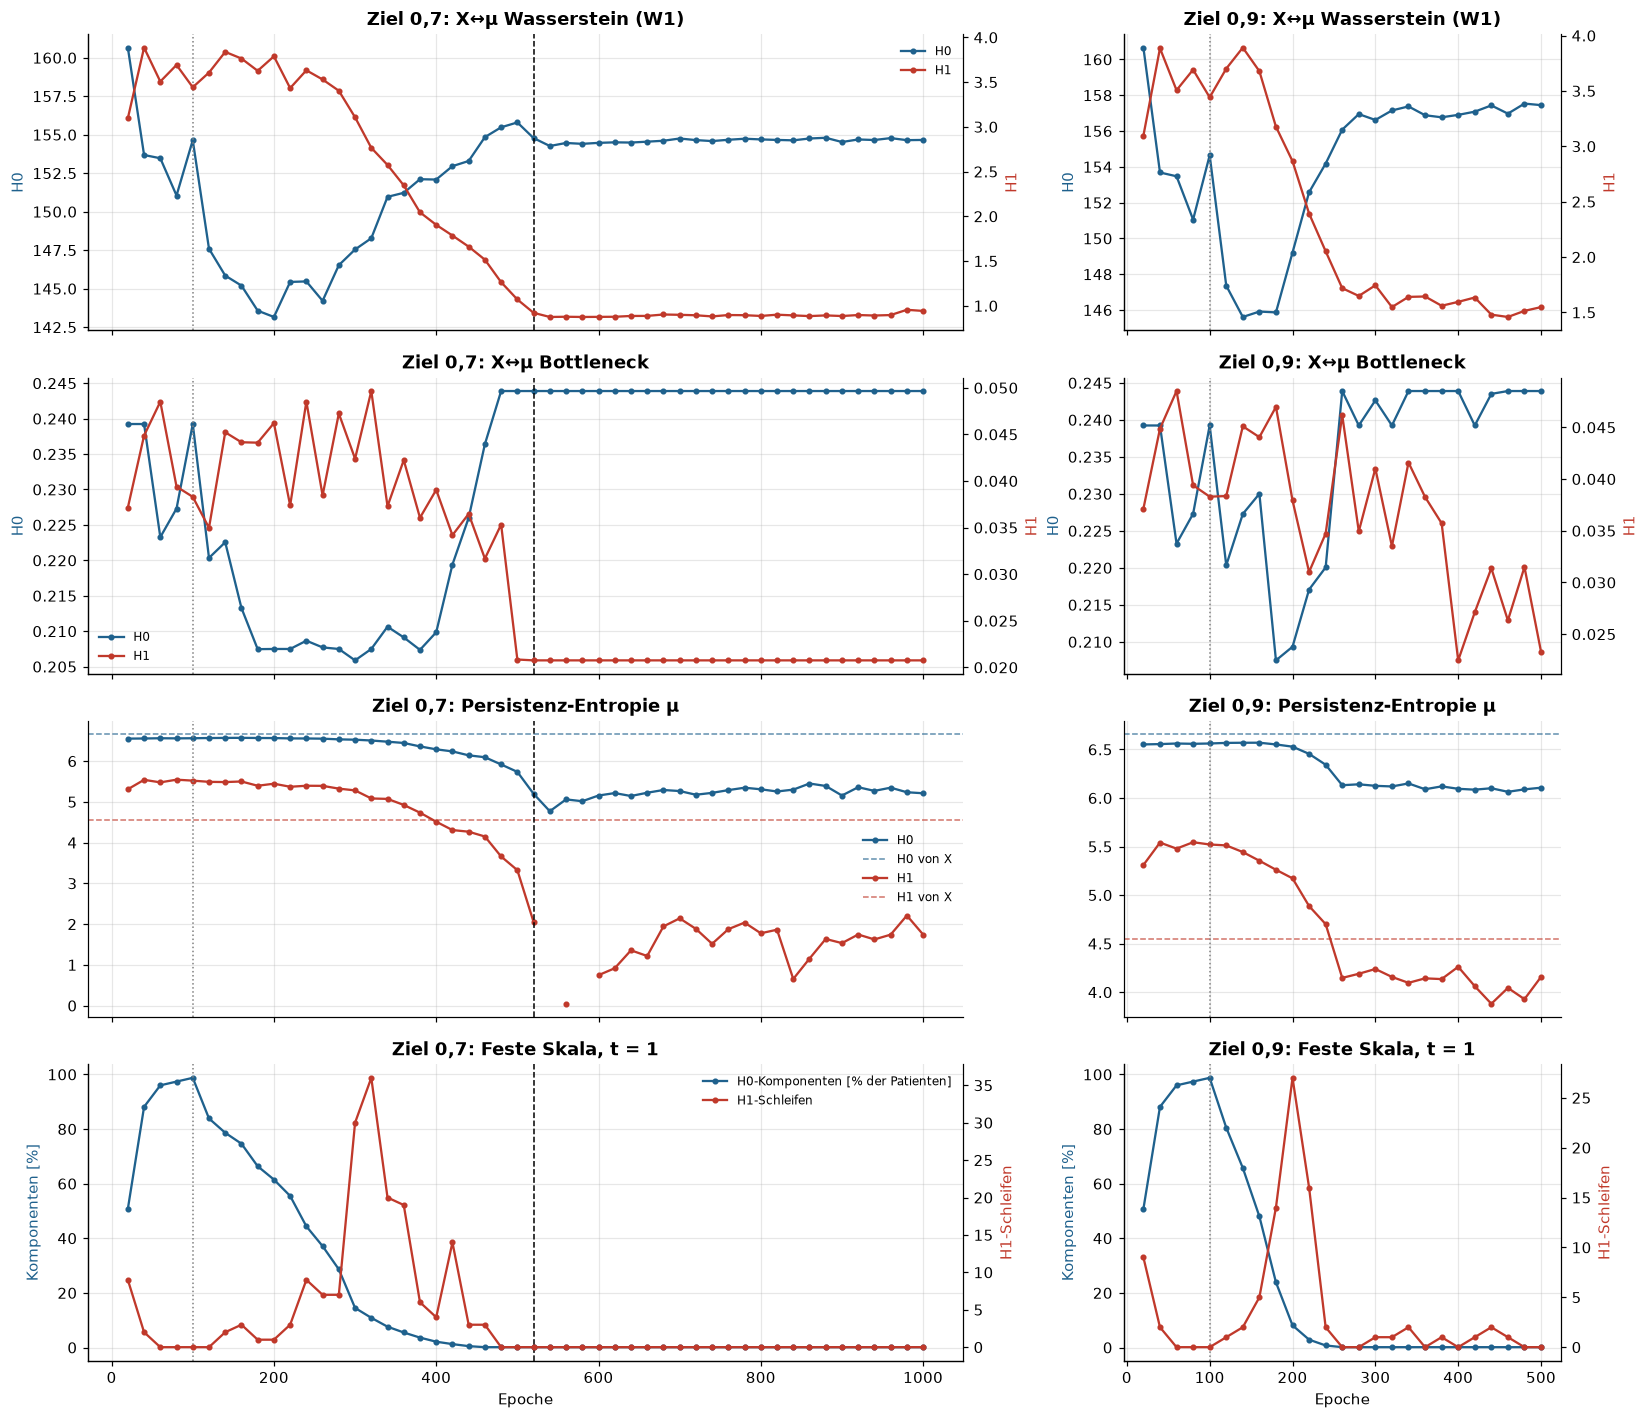

In [10]:
TOPO_PANELS = [
    ("X↔μ Wasserstein (W1)", [("topology_h0_normalized_wasserstein", "H0"), ("topology_h1_normalized_wasserstein", "H1")]),
    ("X↔μ Bottleneck", [("topology_h0_normalized_bottleneck", "H0"), ("topology_h1_normalized_bottleneck", "H1")]),
    ("Persistenz-Entropie μ", [("topology_h0_persistence_entropy_mu", "H0"), ("topology_h1_persistence_entropy_mu", "H1")]),
    ("Feste Skala, t = 1", [("fs_h0_components_share", "H0-Komponenten [% der Patienten]"), ("fs_h1_loops_t1", "H1-Schleifen")]),
]
topology["fs_h0_components_share"] = 100 * topology.fs_h0_components_t1 / 800
fig, axes = plt.subplots(len(TOPO_PANELS), NCOLS, figsize=(7.5 * NCOLS, 13), sharex="col", gridspec_kw=dict(width_ratios=WIDTHS))
for column_index, run in enumerate(COLLAPSE_RUNS):
    group = topology[topology.run.eq(run)].sort_values("epoch")
    for row_index, (title, series) in enumerate(TOPO_PANELS):
        ax = axes[row_index, column_index]
        twin = ax.twinx() if row_index in (0, 1, 3) else None
        for (column, label), color, target in zip(series, ("#1f618d", "#c0392b"), (ax, twin or ax)):
            target.plot(group.epoch, group[column], "o-", ms=3, color=color, label=label)
            if row_index == 2:
                reference = group[column.replace("_mu", "_x")].median()
                ax.axhline(reference, color=color, ls="--", lw=1, alpha=.7, label=f"{label} von X")
        if twin is not None:
            twin.set_ylabel("H1-Schleifen" if row_index == 3 else "H1", color="#c0392b")
            twin.spines["right"].set_visible(True); twin.grid(False)
            ax.set_ylabel("Komponenten [%]" if row_index == 3 else "H0", color="#1f618d")
        if run in first_collapse:
            ax.axvline(first_collapse[run], color="black", ls="--", lw=1)
        ax.axvline(REFERENCE_EPOCH, color="gray", ls=":", lw=1)
        ax.set_title(f"{run}: {title}")
        if column_index == 0:
            handles = ax.get_legend_handles_labels()[0] + (twin.get_legend_handles_labels()[0] if twin else [])
            ax.legend(handles=handles, fontsize=8, loc="best")
    axes[-1, column_index].set_xlabel("Epoche")
fig.tight_layout(); fig.savefig(TOPOLOGY_ROOT / "topology_over_epochs.png", dpi=160); plt.show()

### 9.2 Persistenzdiagramme vor, beim und nach dem Collapse

H1-Diagramme (Geburt gegen Tod, durchmesser-normiert) von X (grau) und μ (farbig) im kollabierenden Lauf an vier Zeitpunkten,
darunter die H0-Todeszeiten von μ (wann verschmelzen Patienten zu einer Komponente). Identische μ (z. B. Patienten
bei μ = 0) verschmelzen bei 0; Ripser gibt Balken der Länge 0 nicht aus, deshalb steht ihre Zahl im Titel
(800 minus Zahl verschiedener μ). Viele Punkte nahe der Diagonale sind
kurzlebige Schleifen (Rauschen); weit oben liegende sind persistente Strukturen.

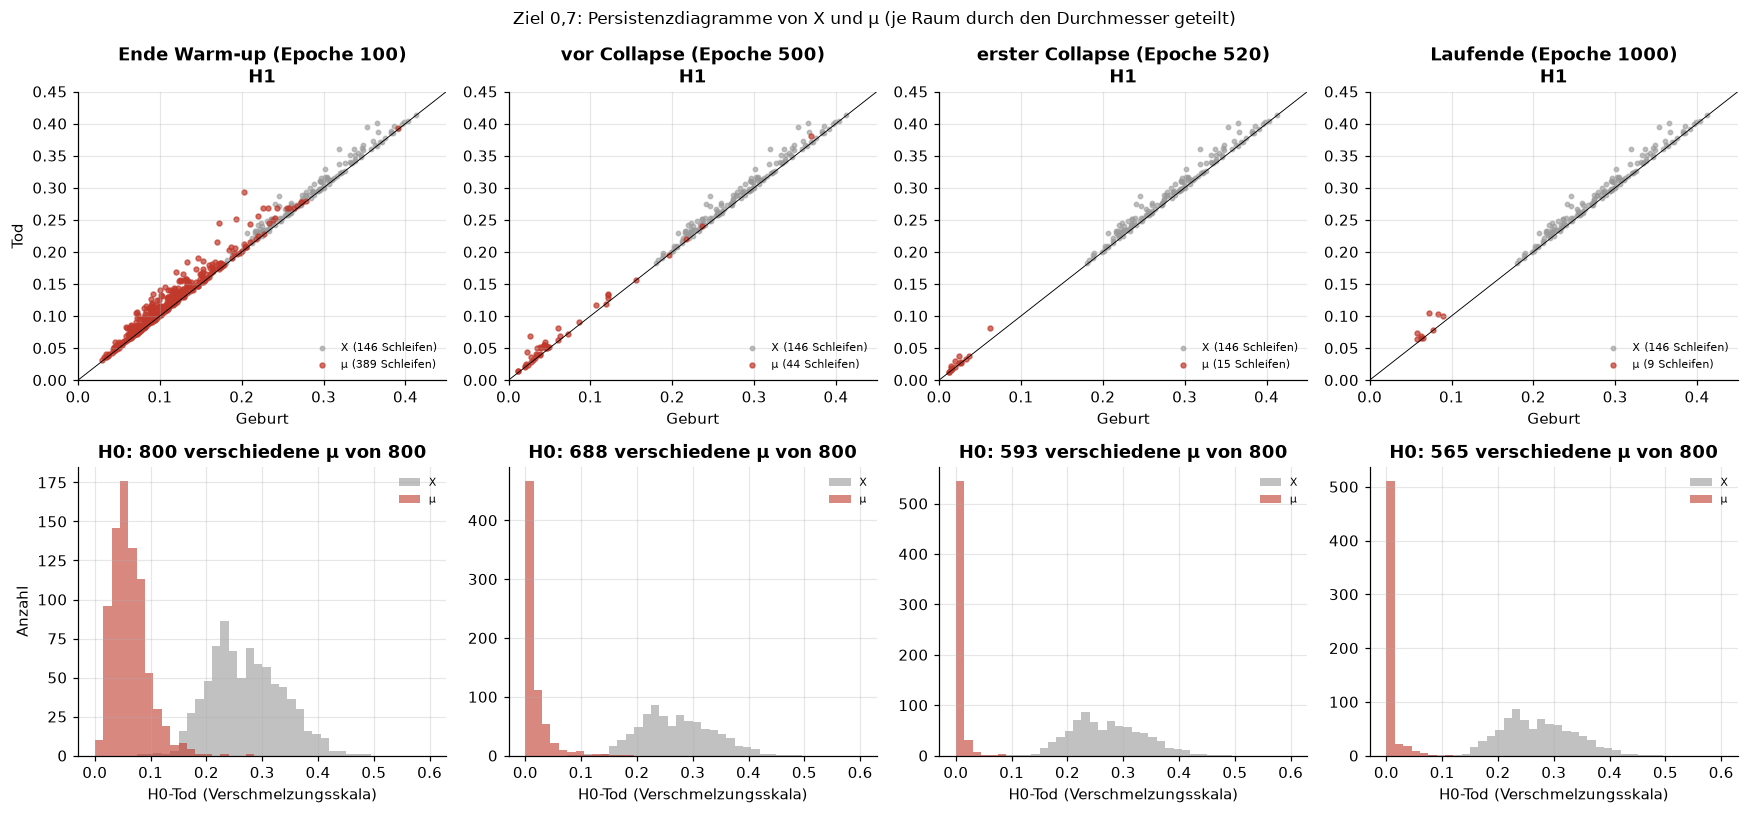

In [11]:
run = "Ziel 0,7"
moments = {"Ende Warm-up": REFERENCE_EPOCH, "vor Collapse": first_collapse[run] - 20,
           "erster Collapse": first_collapse[run], "Laufende": snapshots[snapshots.run.eq(run)].epoch.max()}
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for column_index, (moment, epoch) in enumerate(moments.items()):
    path = TOPOLOGY_ROOT / f"diagrams_{COLLAPSE_RUNS[run]}_{epoch:05d}.npz"
    with np.load(path) as saved:
        x_h1, mu_h1 = saved["topology_input_h1_persistence_diagram"], saved["topology_latent_h1_persistence_diagram"]
        x_h0, mu_h0 = saved["topology_input_h0_persistence_diagram"], saved["topology_latent_h0_persistence_diagram"]
    ax = axes[0, column_index]
    ax.scatter(x_h1[:, 0], x_h1[:, 1], s=8, color="#999999", alpha=.6, label=f"X ({len(x_h1)} Schleifen)")
    ax.scatter(mu_h1[:, 0], mu_h1[:, 1], s=10, color=RUN_COLORS[run], alpha=.7, label=f"μ ({len(mu_h1)} Schleifen)")
    ax.plot([0, 1], [0, 1], color="black", lw=.6)
    ax.set(xlim=(0, .45), ylim=(0, .45), xlabel="Geburt", ylabel="Tod" if column_index == 0 else None,
           title=f"{moment} (Epoche {epoch})\nH1")
    ax.legend(fontsize=7, loc="lower right")
    ax = axes[1, column_index]
    finite_mu, finite_x = mu_h0[np.isfinite(mu_h0[:, 1]), 1], x_h0[np.isfinite(x_h0[:, 1]), 1]
    bins = np.linspace(0, .6, 41)
    ax.hist(finite_x, bins=bins, color="#999999", alpha=.6, label="X")
    ax.hist(finite_mu, bins=bins, color=RUN_COLORS[run], alpha=.6, label="μ")
    distinct = topology[(topology.run == run) & (topology.epoch == epoch)].distinct_mu.iloc[0]
    ax.set(xlabel="H0-Tod (Verschmelzungsskala)", ylabel="Anzahl" if column_index == 0 else None,
           title=f"H0: {distinct} verschiedene μ von 800")
    ax.legend(fontsize=7)
fig.suptitle(f"{run}: Persistenzdiagramme von X und μ (je Raum durch den Durchmesser geteilt)", fontsize=11)
fig.tight_layout(); fig.savefig(TOPOLOGY_ROOT / "persistence_diagrams_collapse.png", dpi=160); plt.show()

### 9.3 Wo stehen die Topologie-Signale in der Zerstörungsreihenfolge?

Wie in 8.1: erste Snapshot-Epoche, ab der sich ein Signal gegenüber dem Warm-up-Ende um 5 % bzw. 20 % verschlechtert.
Für Wasserstein/Bottleneck heißt verschlechtern: steigen; für die Komponenten bei fester Skala: fallen. Die Entropie hat
keine eindeutig gute Richtung, gezählt wird deshalb die absolute relative Änderung. Zum Vergleich stehen die Zeitpunkte
aus 8.1 (Trustworthiness, AUC, Dimensionen) mit in der Tabelle.

run,signal,quelle,epoch_5%,epoch_20%,referenz
"Ziel 0,7",Komponenten bei t = 1,Topologie,120.000000,140.000000,790.000
"Ziel 0,7",Bottleneck H1 X↔μ,Topologie,140.000000,200.000000,0.038
"Ziel 0,7",W1 H1 X↔μ,Topologie,140.000000,–,3.442
"Ziel 0,7",Rekonstruktionsfehler,Abschnitt 8.1,200.000000,320.000000,–
"Ziel 0,7",Entropie H1 μ,Topologie,320.000000,420.000000,5.521
"Ziel 0,7",AUC Geschlecht,Abschnitt 8.1,320.000000,460.000000,–
"Ziel 0,7",Cohesiveness,Abschnitt 8.1,340.000000,–,–
"Ziel 0,7",AUC Krebsart,Abschnitt 8.1,400.000000,480.000000,–
"Ziel 0,7",Entropie H0 μ,Topologie,440.000000,520.000000,6.562
"Ziel 0,7",Trustworthiness,Abschnitt 8.1,480.000000,520.000000,–


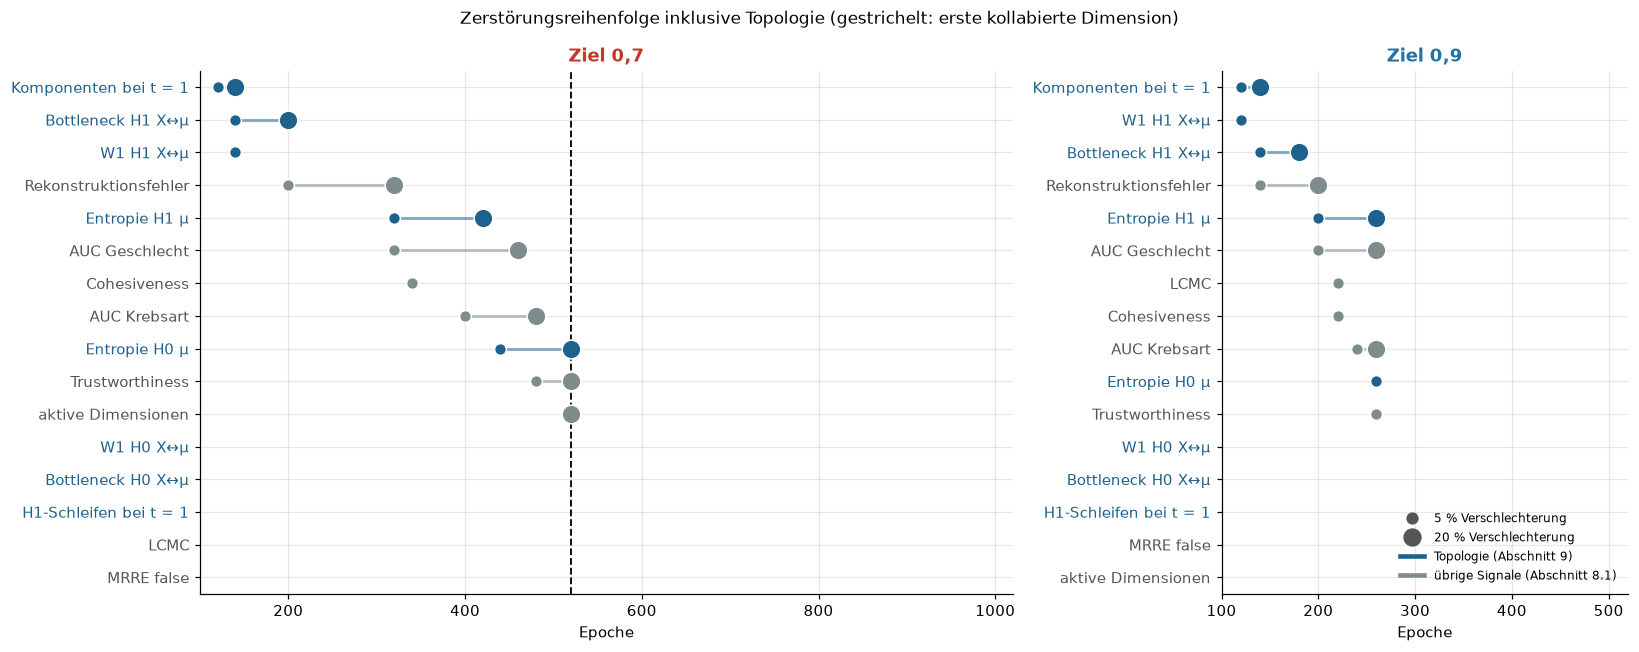

In [12]:
TOPO_SIGNALS = {"topology_h0_normalized_wasserstein": ("W1 H0 X↔μ", -1), "topology_h1_normalized_wasserstein": ("W1 H1 X↔μ", -1),
                "topology_h0_normalized_bottleneck": ("Bottleneck H0 X↔μ", -1), "topology_h1_normalized_bottleneck": ("Bottleneck H1 X↔μ", -1),
                "topology_h0_persistence_entropy_mu": ("Entropie H0 μ", 0), "topology_h1_persistence_entropy_mu": ("Entropie H1 μ", 0),
                "fs_h0_components_t1": ("Komponenten bei t = 1", +1), "fs_h1_loops_t1": ("H1-Schleifen bei t = 1", 0)}
rows = []
for run, group in topology.groupby("run"):
    group = group[group.epoch >= REFERENCE_EPOCH].sort_values("epoch").reset_index(drop=True)
    for column, (label, direction) in TOPO_SIGNALS.items():
        reference = group.loc[group.epoch.eq(REFERENCE_EPOCH), column].iloc[0]
        change = (group[column] - reference) / abs(reference) if reference != 0 else group[column] * np.nan
        loss = change.abs() if direction == 0 else (-change if direction > 0 else change)
        row = dict(run=run, signal=label, quelle="Topologie")
        for threshold in (0.05, 0.20):
            hit = group[loss >= threshold]
            row[f"epoch_{threshold:.0%}"] = hit.epoch.iloc[0] if len(hit) else np.nan
        row["referenz"] = reference
        rows.append(row)
combined = pd.concat([pd.DataFrame(rows), destruction_order.assign(quelle="Abschnitt 8.1")[["run", "signal", "quelle", "epoch_5%", "epoch_20%"]]])
combined = combined.sort_values(["run", "epoch_5%", "epoch_20%"], na_position="last")
combined.to_csv(TOPOLOGY_ROOT / "destruction_order_with_topology.csv", index=False)
display(combined.style.format(precision=0, na_rep="–").format({"referenz": "{:.3f}"}, na_rep="–").hide(axis="index"))

fig, axes = plt.subplots(1, NCOLS, figsize=(7.5 * NCOLS, 6), gridspec_kw=dict(width_ratios=WIDTHS))
for ax, run in zip(axes, COLLAPSE_RUNS):
    table = combined[combined.run.eq(run)].reset_index(drop=True)
    for y, row in table.iterrows():
        color = "#1f618d" if row.quelle == "Topologie" else "#7f8c8d"
        for column, size in (("epoch_5%", 60), ("epoch_20%", 150)):
            if np.isfinite(row[column]):
                ax.scatter(row[column], y, s=size, color=color, edgecolor="white", zorder=3)
        if np.isfinite(row["epoch_5%"]) and np.isfinite(row["epoch_20%"]):
            ax.plot([row["epoch_5%"], row["epoch_20%"]], [y, y], color=color, lw=2, alpha=.5)
    if run in first_collapse:
        ax.axvline(first_collapse[run], color="black", ls="--", lw=1.2)
    ax.set(yticks=range(len(table)), yticklabels=table.signal, ylim=(len(table) - .5, -.5),
           xlim=(REFERENCE_EPOCH, snapshots[snapshots.run.eq(run)].epoch.max() + 20), xlabel="Epoche", title=run)
    ax.title.set_color(RUN_COLORS[run])
    for label, row in zip(ax.get_yticklabels(), table.itertuples()):
        label.set_color("#1f618d" if row.quelle == "Topologie" else "#555555")
legend = [Line2D([], [], ls="", marker="o", ms=7, color="#555555", label="5 % Verschlechterung"),
          Line2D([], [], ls="", marker="o", ms=11, color="#555555", label="20 % Verschlechterung"),
          Line2D([], [], color="#1f618d", lw=3, label="Topologie (Abschnitt 9)"),
          Line2D([], [], color="#7f8c8d", lw=3, label="übrige Signale (Abschnitt 8.1)")]
axes[-1].legend(handles=legend, fontsize=8, loc="lower right")
fig.suptitle("Zerstörungsreihenfolge inklusive Topologie (gestrichelt: erste kollabierte Dimension)", fontsize=11)
fig.tight_layout(); fig.savefig(TOPOLOGY_ROOT / "destruction_order_with_topology.png", dpi=160); plt.show()

### 9.4 Einordnung

(wird nach der Auswertung ergänzt)

## 10. UMAP und Ridgelines aus AUTOENCODIX

AUTOENCODIX zeichnet den Latentraum mit `show_latent_space`: `UMAP(n_components=2)` auf dem gespeicherten Latentraum z
und `GeneralVisualizer._plot_2D` für das Streudiagramm (Gruppenmittelwerte als große Punkte). Unsere Läufe speichern kein
AUTOENCODIX-`Result`-Objekt, deshalb werden genau diese beiden Bausteine direkt auf die z-Snapshots angewendet
(Train + Validation, wie `split="all"`). Einzige Abweichung: `random_state=0` für reproduzierbare UMAPs.
Pro Lauf vier Zeitpunkte: Ende Warm-up, letzter Snapshot vor dem Collapse (bzw. Epoche 260, wenn der Lauf das Zielband erreicht),
erster Collapse (bzw. Mitte) und Laufende. Gefärbt nach den acht Präsentations-Krebsarten (übrige grau) und nach Geschlecht.

Achtung bei der Interpretation: UMAP ist nichtlinear und zeigt lokale Nachbarschaft, keine Abstände; Größe und Lage
der Wolken sind zwischen Panels nicht vergleichbar. Kollabierte Dimensionen sind in z reines N(0,1)-Rauschen und
verwischen die UMAP zusätzlich.

/home/nickok/Projects/MasterThesis/vae-beta-control/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/nickok/Projects/MasterThesis/vae-beta-control/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/nickok/Projects/MasterThesis/vae-beta-control/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/nickok/Projects/MasterThesis/vae-beta-control/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/nickok/Projects/MasterThesis/vae-beta-control/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to

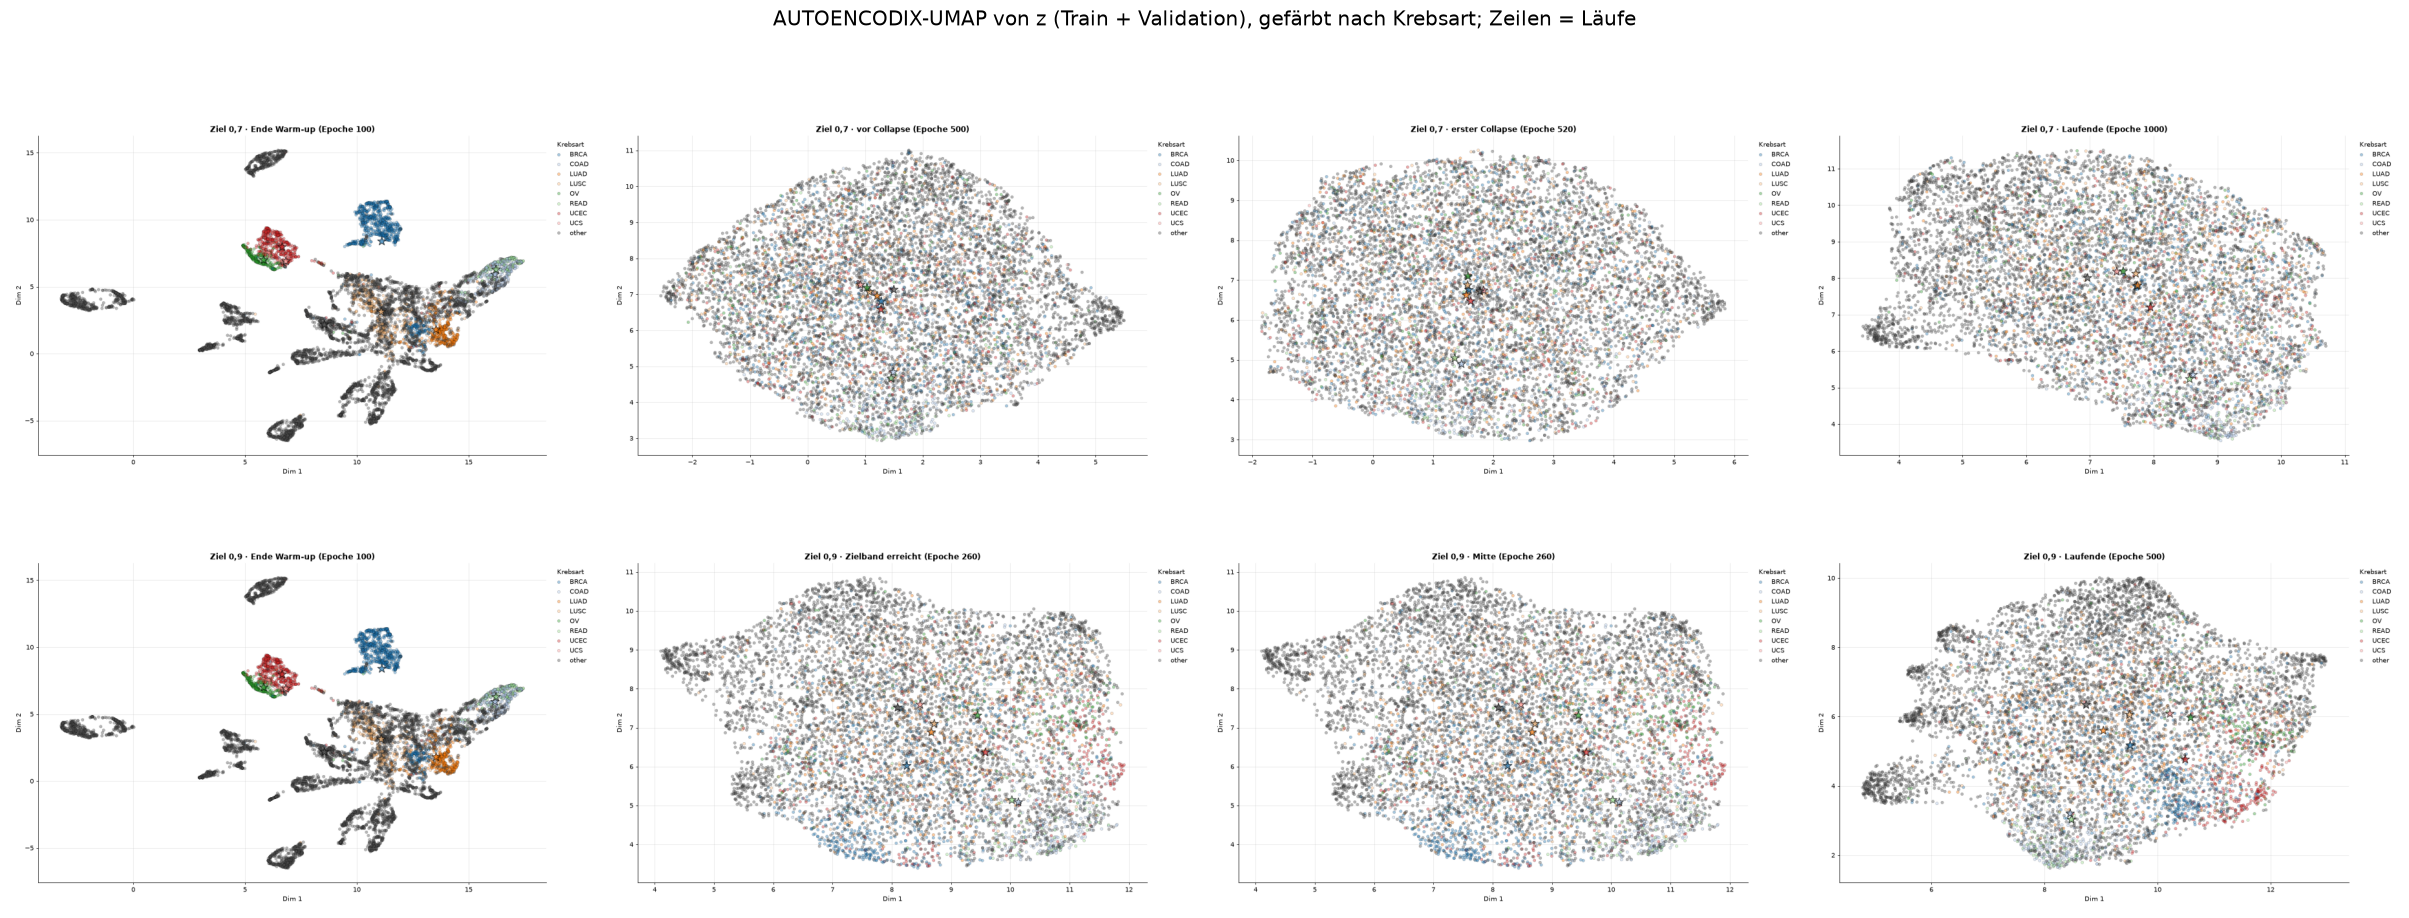

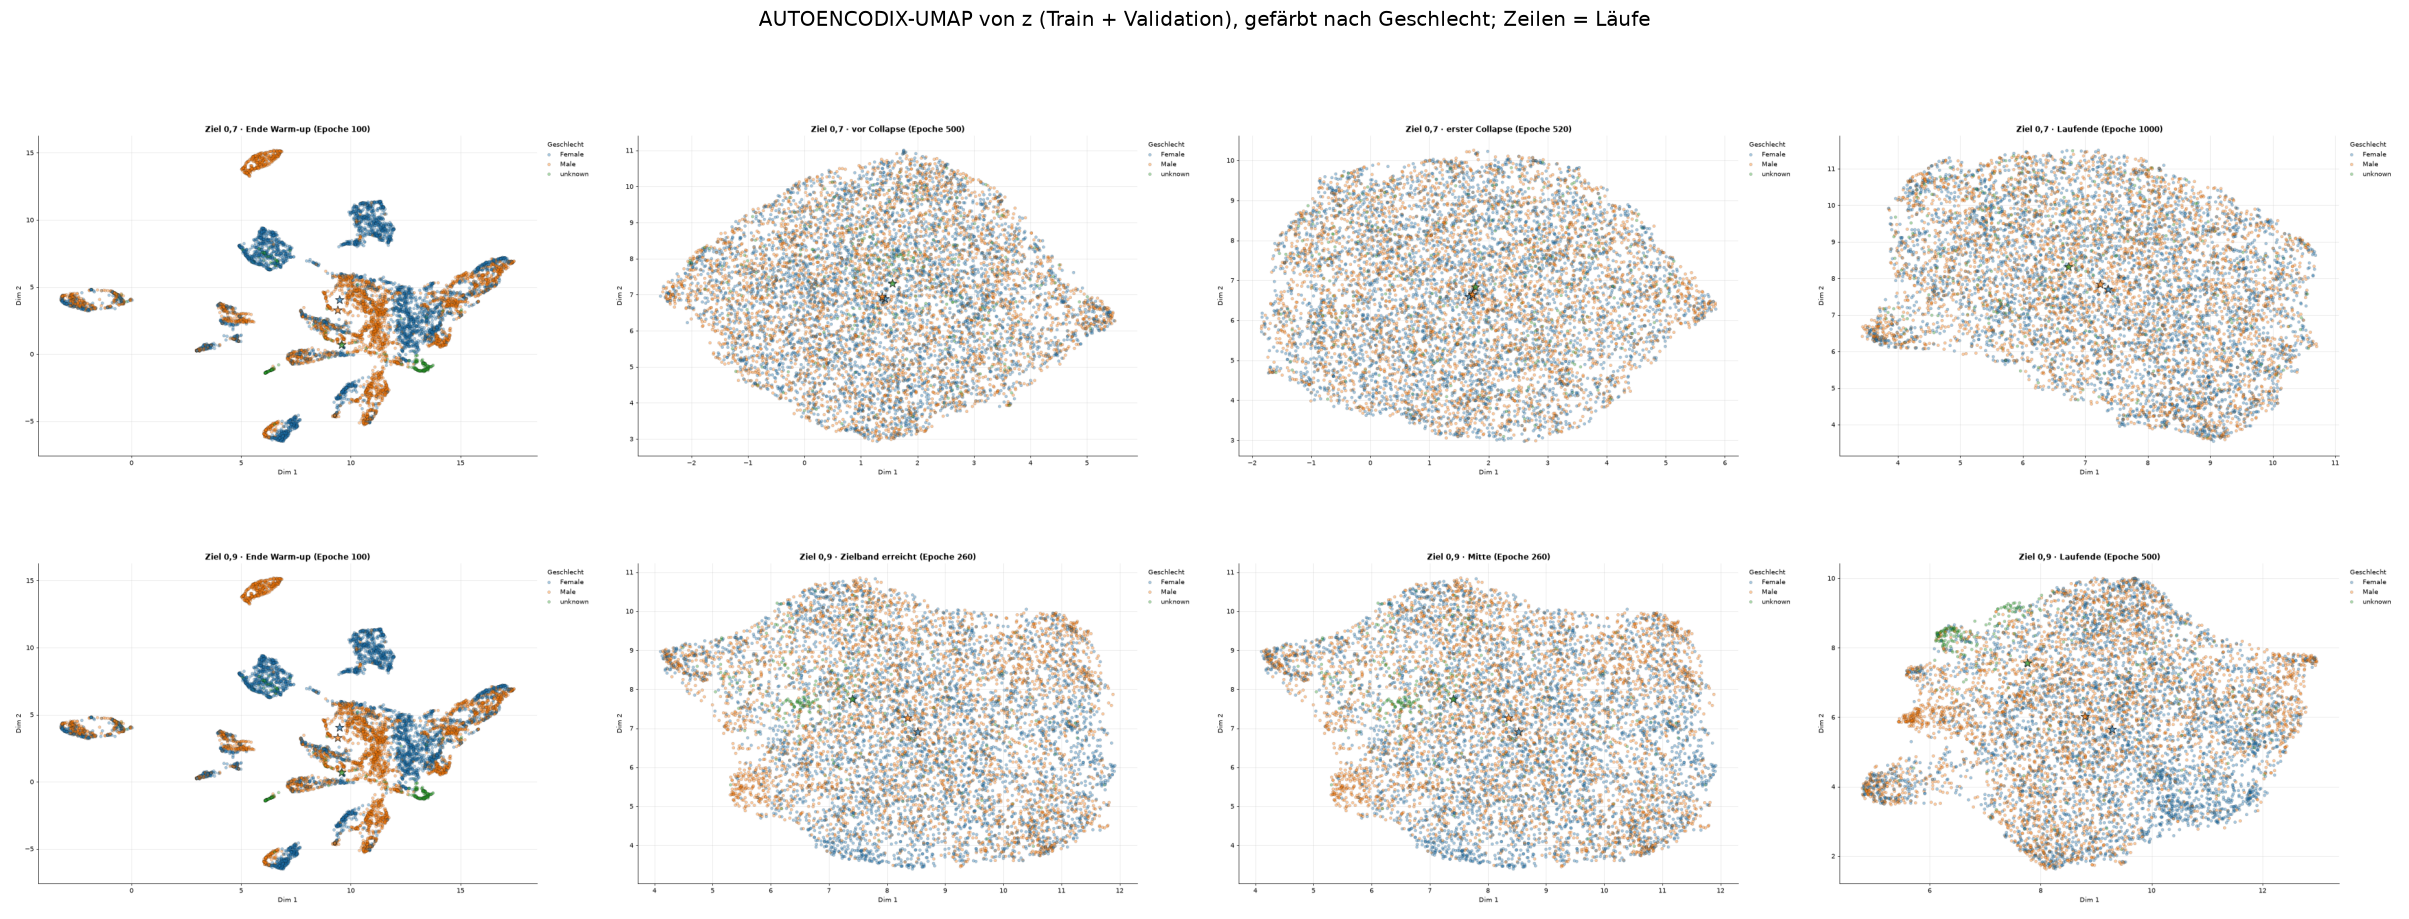

In [13]:
import io
import warnings as _warnings
from umap import UMAP
from autoencodix.visualize._general_visualizer import GeneralVisualizer

PRESENTATION = ("BRCA", "COAD", "LUAD", "LUSC", "OV", "READ", "UCEC", "UCS")


def umap_moments(run):
    epochs = sorted(snapshots[snapshots.run.eq(run)].epoch)
    if run in first_collapse:
        chosen = [REFERENCE_EPOCH, first_collapse[run] - 20, first_collapse[run], epochs[-1]]
        names = ["Ende Warm-up", "vor Collapse", "erster Collapse", "Laufende"]
    else:
        chosen = [REFERENCE_EPOCH, 260, epochs[len(epochs) // 2], epochs[-1]]
        names = ["Ende Warm-up", "Zielband erreicht", "Mitte", "Laufende"]
    return dict(zip(names, chosen))


def load_z(run, epoch):
    folder = run_folder(run)
    frames, label_frames = [], []
    for split in ("train", "valid"):
        with np.load(folder / "epoch_snapshots" / f"epoch_{epoch:05d}_{split}.npz") as saved:
            frames.append(pd.DataFrame(saved["z"], index=saved["sample_ids"].astype(str)))
        labels = pd.read_parquet(folder / "epoch_snapshots" / f"labels_{split}.parquet")
        labels.index = labels.index.astype(str)
        label_frames.append(labels.loc[frames[-1].index, ["CANCER_TYPE_ACRONYM", "SEX"]])
    return pd.concat(frames), pd.concat(label_frames)


def figure_to_image(figure):
    buffer = io.BytesIO()
    figure.savefig(buffer, format="png", dpi=70, bbox_inches="tight")
    plt.close(figure)
    buffer.seek(0)
    return plt.imread(buffer)


umap_images = {}
for run in COLLAPSE_RUNS:
    for moment, epoch in umap_moments(run).items():
        z, labels = load_z(run, epoch)
        embedding = pd.DataFrame(UMAP(n_components=2, random_state=0).fit_transform(z), index=z.index)
        for param, values, focus in (("Krebsart", labels.CANCER_TYPE_ACRONYM.fillna("unknown"), list(PRESENTATION)),
                                     ("Geschlecht", labels.SEX.fillna("unknown"), None)):
            with _warnings.catch_warnings():
                _warnings.simplefilter("ignore")
                figure = GeneralVisualizer._plot_2D(embedding=embedding.reset_index(drop=True), labels=values.tolist(),
                                                    focus_labels=focus, param=param,
                                                    layer=f"{run} · {moment} (Epoche {epoch})", figsize=(12, 8), center=True)
            umap_images[(param, run, moment)] = figure_to_image(figure)

for param in ("Krebsart", "Geschlecht"):
    fig, axes = plt.subplots(NCOLS, 4, figsize=(22, 4.6 * NCOLS))
    for row, run in enumerate(COLLAPSE_RUNS):
        for column, moment in enumerate(umap_moments(run)):
            ax = axes[row, column]
            ax.imshow(umap_images[(param, run, moment)])
            ax.set_axis_off()
    fig.suptitle(f"AUTOENCODIX-UMAP von z (Train + Validation), gefärbt nach {param}; Zeilen = Läufe", fontsize=13)
    fig.tight_layout()
    fig.savefig(COLLAPSE_ROOT / f"umap_autoencodix_{'cancer' if param == 'Krebsart' else 'sex'}.png", dpi=130)
    plt.show()

### 10.1 Ridgeline der latenten Dimensionen (AUTOENCODIX `_plot_latent_ridge`)

Dichte jeder z-Dimension, getrennt nach Geschlecht, im kollabierenden Lauf vor und nach dem Collapse. Eine kollabierte
Dimension wird zu einer für beide Gruppen identischen Standardnormalverteilung; eine label-tragende Dimension zeigt
verschobene Gipfel.

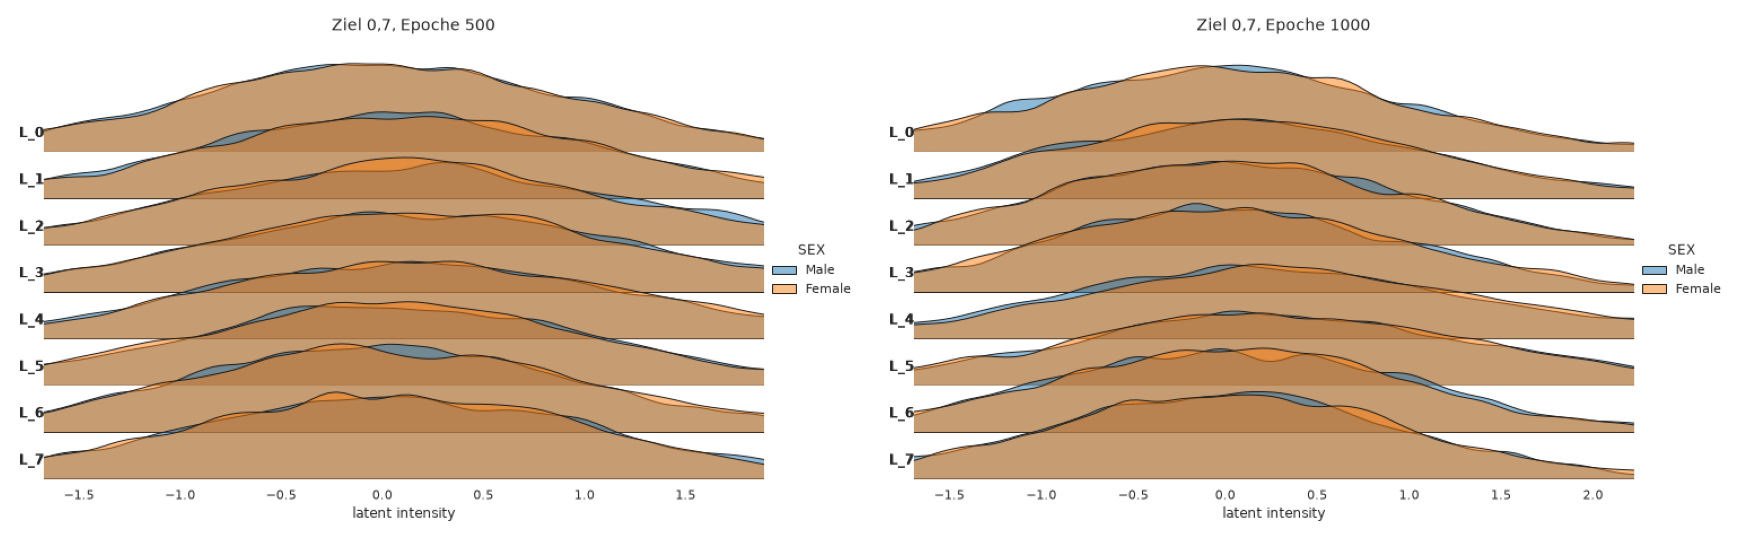

In [14]:
if "Ziel 0,7" in first_collapse:
    run = "Ziel 0,7"
    ridge_images = []
    for epoch in (first_collapse[run] - 20, snapshots[snapshots.run.eq(run)].epoch.max()):
        z, labels = load_z(run, epoch)
        z.columns = [f"L_{dim}" for dim in z.columns]
        with _warnings.catch_warnings():
            _warnings.simplefilter("ignore")
            grid = GeneralVisualizer._plot_latent_ridge(lat_space=z.copy(), labels=labels.SEX.fillna("unknown").tolist(),
                                                        param="SEX")
        grid.figure.suptitle(f"{run}, Epoche {epoch}", y=1.02)
        ridge_images.append(figure_to_image(grid.figure))
    fig, axes = plt.subplots(1, 2, figsize=(16, 9))
    for ax, image in zip(axes, ridge_images):
        ax.imshow(image); ax.set_axis_off()
    fig.tight_layout(); fig.savefig(COLLAPSE_ROOT / "ridgeline_autoencodix_sex.png", dpi=130); plt.show()